In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Car details v3.csv to Car details v3 (1).csv


In [ ]:
import pandas as pd

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [ ]:
print("Number of car records:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of car records: 8128
Number of columns: 13


In [ ]:
df.isna().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,221
engine,221


In [ ]:
duplicate_count = df.duplicated().sum()

print("Number of extra duplicate rows:", duplicate_count)

Number of extra duplicate rows: 1202


In [ ]:
df = df.drop_duplicates().reset_index(drop=True)

print("Remaining records:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Duplicate rows remaining:", df.duplicated().sum())

Remaining records: 6926
Number of columns: 13
Duplicate rows remaining: 0


In [ ]:
df["brand"] = df["name"].str.strip().str.split().str[0]

df["brand"] = df["brand"].replace({
    "Land": "Land Rover",
    "Ashok": "Ashok Leyland",
    "ISUZU": "Isuzu"
})

df[["name", "brand"]].head(10)

,name,brand
0,Maruti Swift Dzire VDI,Maruti
1,Skoda Rapid 1.5 TDI Ambition,Skoda
2,Honda City 2017-2020 EXi,Honda
3,Hyundai i20 Sportz Diesel,Hyundai
4,Maruti Swift VXI BSIII,Maruti
5,Hyundai Xcent 1.2 VTVT E Plus,Hyundai
6,Maruti Wagon R LXI DUO BSIII,Maruti
7,Maruti 800 DX BSII,Maruti
8,Toyota Etios VXD,Toyota
9,Ford Figo Diesel Celebration Edition,Ford


In [ ]:
df["engine"] = pd.to_numeric(
    df["engine"].astype("string").str.replace("CC", "", regex=False).str.strip(),
    errors="coerce"
)

df[["engine"]].head(10)

,engine
0,1248
1,1498
2,1497
3,1396
4,1298
5,1197
6,1061
7,796
8,1364
9,1399


In [ ]:
df["max_power"] = pd.to_numeric(
    df["max_power"].astype("string").str.replace("bhp", "", regex=False).str.strip(),
    errors="coerce"
)

df[["max_power"]].head(10)

,max_power
0,74.0
1,103.52
2,78.0
3,90.0
4,88.2
5,81.86
6,57.5
7,37.0
8,67.1
9,68.1


In [ ]:
mileage_parts = df["mileage"].astype("string").str.split()

df["mileage_value"] = pd.to_numeric(
    mileage_parts.str[0], errors="coerce"
)

df["mileage_unit"] = mileage_parts.str[1]

df[["mileage", "mileage_value", "mileage_unit"]].head(10)

,mileage,mileage_value,mileage_unit
0,23.4 kmpl,23.40,kmpl
1,21.14 kmpl,21.14,kmpl
2,17.7 kmpl,17.70,kmpl
3,23.0 kmpl,23.00,kmpl
4,16.1 kmpl,16.10,kmpl
5,20.14 kmpl,20.14,kmpl
6,17.3 km/kg,17.30,km/kg
7,16.1 kmpl,16.10,kmpl
8,23.59 kmpl,23.59,kmpl
9,20.0 kmpl,20.00,kmpl


In [ ]:
numeric_columns = [
    "year",
    "selling_price",
    "km_driven",
    "mileage_value",
    "engine",
    "max_power",
    "seats"
]

df[numeric_columns].describe().T[["count", "min", "max"]]

,count,min,max
year,6926.0,1983.0,2020.0
selling_price,6926.0,29999.0,10000000.0
km_driven,6926.0,1.0,2360457.0
mileage_value,6718.0,0.0,42.0
engine,6718.0,624.0,3604.0
max_power,6720.0,0.0,400.0
seats,6718.0,2.0,14.0


In [ ]:
positive_columns = ["mileage_value", "engine", "max_power", "seats"]

for column in positive_columns:
    invalid = df[column] <= 0
    print(column, "- invalid values found:", invalid.sum())

    df.loc[invalid, column] = pd.NA

invalid_km = df["km_driven"] < 0
print("km_driven - invalid values found:", invalid_km.sum())

df.loc[invalid_km, "km_driven"] = pd.NA

mileage_value - invalid values found: 15
engine - invalid values found: 0
max_power - invalid values found: 3
seats - invalid values found: 0
km_driven - invalid values found: 0


In [ ]:
df["selling_price"] = pd.to_numeric(df["selling_price"], errors="coerce")

invalid_price = df["selling_price"].isna() | (df["selling_price"] <= 0)

print("Records with invalid selling prices:", invalid_price.sum())

df = df.loc[~invalid_price].copy()

print("Remaining records:", len(df))

Records with invalid selling prices: 0
Remaining records: 6926


In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED
)

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Test records:", len(test_df))

Training records: 4848
Validation records: 1039
Test records: 1039


In [ ]:
REFERENCE_YEAR = int(train_df["year"].max())

for dataset in [train_df, val_df, test_df]:
    dataset["car_age"] = REFERENCE_YEAR - dataset["year"]

print("Reference year:", REFERENCE_YEAR)

train_df[["year", "car_age"]].head(10)

Reference year: 2020


,year,car_age
47,2014,6
4002,2018,2
1350,2018,2
4635,2018,2
446,2011,9
1743,2015,5
5407,2018,2
2921,2019,1
4917,2011,9
3621,2012,8


In [ ]:
median_columns = ["car_age", "km_driven", "engine", "max_power"]

training_medians = train_df[median_columns].median()

for dataset in [train_df, val_df, test_df]:
    dataset[median_columns] = dataset[median_columns].fillna(training_medians)

pd.DataFrame({
    "Training": train_df[median_columns].isna().sum(),
    "Validation": val_df[median_columns].isna().sum(),
    "Test": test_df[median_columns].isna().sum()
})

,Training,Validation,Test
car_age,0,0,0
km_driven,0,0,0
engine,0,0,0
max_power,0,0,0


In [ ]:
seat_fill_value = train_df["seats"].mode().iloc[0]

for dataset in [train_df, val_df, test_df]:
    dataset["seats"] = dataset["seats"].fillna(seat_fill_value)

print("Seat count used for filling:", seat_fill_value)

pd.DataFrame({
    "Training": train_df[["seats"]].isna().sum(),
    "Validation": val_df[["seats"]].isna().sum(),
    "Test": test_df[["seats"]].isna().sum()
})

Seat count used for filling: 5.0


,Training,Validation,Test
seats,0,0,0


In [ ]:
unit_by_fuel = (
    train_df.dropna(subset=["mileage_unit"])
    .groupby("fuel")["mileage_unit"]
    .agg(lambda units: units.mode().iloc[0])
)

for dataset in [train_df, val_df, test_df]:
    inferred_units = dataset["fuel"].map(unit_by_fuel)
    dataset["mileage_unit"] = dataset["mileage_unit"].fillna(inferred_units)

print("Mileage units learned from training data:")
print(unit_by_fuel)

pd.DataFrame({
    "Training": train_df[["mileage_unit"]].isna().sum(),
    "Validation": val_df[["mileage_unit"]].isna().sum(),
    "Test": test_df[["mileage_unit"]].isna().sum()
})

Mileage units learned from training data:
fuel
CNG       km/kg
Diesel     kmpl
LPG       km/kg
Petrol     kmpl
Name: mileage_unit, dtype: object


,Training,Validation,Test
mileage_unit,0,0,0


In [ ]:
mileage_medians = (
    train_df.groupby("mileage_unit")["mileage_value"].median()
)

for dataset in [train_df, val_df, test_df]:
    replacement_values = dataset["mileage_unit"].map(mileage_medians)
    dataset["mileage_value"] = dataset["mileage_value"].fillna(
        replacement_values
    )

print("Mileage medians learned from training data:")
print(mileage_medians)

pd.DataFrame({
    "Training": train_df[["mileage_value"]].isna().sum(),
    "Validation": val_df[["mileage_value"]].isna().sum(),
    "Test": test_df[["mileage_value"]].isna().sum()
})

Mileage medians learned from training data:
mileage_unit
km/kg    21.94
kmpl     19.40
Name: mileage_value, dtype: float64


,Training,Validation,Test
mileage_value,0,0,0


In [ ]:
numeric_features = [
    "car_age", "km_driven", "mileage_value",
    "engine", "max_power", "seats"
]

categorical_features = [
    "brand", "fuel", "seller_type",
    "transmission", "owner", "mileage_unit"
]

feature_columns = numeric_features + categorical_features

X_train = train_df[feature_columns].copy()
y_train = train_df["selling_price"].copy()

X_val = val_df[feature_columns].copy()
y_val = val_df["selling_price"].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df["selling_price"].copy()

print("Training inputs:", X_train.shape)
print("Validation inputs:", X_val.shape)
print("Test inputs:", X_test.shape)

Training inputs: (4848, 12)
Validation inputs: (1039, 12)
Test inputs: (1039, 12)


In [ ]:
from sklearn.preprocessing import OneHotEncoder

baseline_encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

X_train_cat = baseline_encoder.fit_transform(
    X_train[categorical_features]
)

X_val_cat = baseline_encoder.transform(X_val[categorical_features])
X_test_cat = baseline_encoder.transform(X_test[categorical_features])

print("Encoded training categories:", X_train_cat.shape)
print("Encoded validation categories:", X_val_cat.shape)
print("Encoded test categories:", X_test_cat.shape)

Encoded training categories: (4848, 39)
Encoded validation categories: (1039, 39)
Encoded test categories: (1039, 39)


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [ ]:
from sklearn.preprocessing import StandardScaler

numeric_scaler = StandardScaler()

X_train_num = numeric_scaler.fit_transform(
    X_train[numeric_features]
)

X_val_num = numeric_scaler.transform(X_val[numeric_features])
X_test_num = numeric_scaler.transform(X_test[numeric_features])

pd.DataFrame(
    X_train_num,
    columns=numeric_features,
    index=X_train.index
).head().round(3)

,car_age,km_driven,mileage_value,engine,max_power,seats
47,-0.143,0.052,-1.768,3.129,2.534,1.586
4002,-1.122,-0.920,0.202,-0.879,-0.624,-0.435
1350,-1.122,-0.266,0.772,-0.075,0.027,-0.435
4635,-1.122,-0.920,1.153,-0.877,-0.657,-0.435
446,0.591,0.670,-0.636,-0.057,-0.532,-0.435


In [ ]:
import numpy as np

X_train_baseline = np.hstack([X_train_num, X_train_cat])

X_val_baseline = np.hstack([X_val_num, X_val_cat])

X_test_baseline = np.hstack([X_test_num, X_test_cat])

print("Training inputs:", X_train_baseline.shape)
print("Validation inputs:", X_val_baseline.shape)
print("Test inputs:", X_test_baseline.shape)

Training inputs: (4848, 45)
Validation inputs: (1039, 45)
Test inputs: (1039, 45)


In [ ]:
from sklearn.linear_model import LinearRegression

baseline_model = LinearRegression()

baseline_model.fit(X_train_baseline, y_train)

print("Linear regression baseline trained successfully.")
print("Training records:", X_train_baseline.shape[0])
print("Input features:", baseline_model.n_features_in_)

Linear regression baseline trained successfully.
Training records: 4848
Input features: 45


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

baseline_val_predictions = baseline_model.predict(X_val_baseline)

baseline_val_results = pd.DataFrame({
    "MAE (₹)": [
        mean_absolute_error(y_val, baseline_val_predictions)
    ],
    "RMSE (₹)": [
        np.sqrt(mean_squared_error(y_val, baseline_val_predictions))
    ],
    "R2 (raw price)": [
        r2_score(y_val, baseline_val_predictions)
    ],
    "MAPE (%)": [
        mean_absolute_percentage_error(y_val, baseline_val_predictions) * 100
    ]
}, index=["Linear regression (validation)"])

baseline_val_results.T.round(4)

,Linear regression (validation)
MAE (₹),135922.1654
RMSE (₹),269613.0713
R2 (raw price),0.6333
MAPE (%),44.4590


In [ ]:
baseline_val_details = pd.DataFrame({
    "Actual price (₹)": y_val,
    "Predicted price (₹)": baseline_val_predictions
})

baseline_val_details["Residual (₹)"] = (
    baseline_val_details["Actual price (₹)"]
    - baseline_val_details["Predicted price (₹)"]
)

baseline_val_details["Absolute error (₹)"] = (
    baseline_val_details["Residual (₹)"].abs()
)

baseline_val_details.sort_values(
    "Absolute error (₹)", ascending=False
).head(10).round(2)

,Actual price (₹),Predicted price (₹),Residual (₹),Absolute error (₹)
132,5150000,2054889.99,3095110.01,3095110.01
135,4500000,1679478.09,2820521.91,2820521.91
3161,550000,-1797807.74,2347807.74,2347807.74
5351,2000000,4200695.87,-2200695.87,2200695.87
4781,3251000,1291636.47,1959363.53,1959363.53
4222,1000000,2833028.54,-1833028.54,1833028.54
1657,3200000,1583115.67,1616884.33,1616884.33
5717,1100000,2607991.88,-1507991.88,1507991.88
2471,1100000,2516193.26,-1416193.26,1416193.26
6577,3200000,1809215.61,1390784.39,1390784.39


In [ ]:
y_train_log = np.log(y_train)
y_val_log = np.log(y_val)

log_price_preview = pd.DataFrame({
    "Original price (₹)": y_train,
    "Log price": y_train_log
})

log_price_preview.head().round(4)

,Original price (₹),Log price
47,1500000,14.2210
4002,350000,12.7657
1350,850000,13.6530
4635,400000,12.8992
446,200000,12.2061


In [ ]:
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)

tf.config.experimental.enable_op_determinism()

print("TensorFlow version:", tf.__version__)
print("Random seed:", SEED)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow version: 2.20.0
Random seed: 42
GPU available: True


In [ ]:
brand_counts = X_train["brand"].value_counts()

MIN_BRAND_COUNT = 5

frequent_brands = sorted(
    brand_counts[brand_counts >= MIN_BRAND_COUNT].index
)

brand_to_id = {
    brand: number
    for number, brand in enumerate(frequent_brands, start=1)
}

def encode_brands(data):
    return (
        data["brand"]
        .map(brand_to_id)
        .fillna(0)
        .to_numpy(dtype="int32")
        .reshape(-1, 1)
    )

X_train_brand = encode_brands(X_train)
X_val_brand = encode_brands(X_val)
X_test_brand = encode_brands(X_test)

num_brand_ids = len(brand_to_id) + 1

print("Number of brand IDs, including Other:", num_brand_ids)
print("Training cars assigned to Other:", (X_train_brand == 0).sum())

pd.DataFrame({
    "Brand": X_train["brand"],
    "Brand ID": X_train_brand.ravel()
}).head(10)

Number of brand IDs, including Other: 22
Training cars assigned to Other: 16


,Brand,Brand ID
47,Toyota,19
4002,Hyundai,8
1350,Hyundai,8
4635,Renault,16
446,Tata,18
1743,Maruti,12
5407,Maruti,12
2921,Hyundai,8
4917,Tata,18
3621,Tata,18


In [ ]:
from sklearn.preprocessing import OneHotEncoder

ann_categorical_features = [
    "fuel", "seller_type", "transmission",
    "owner", "mileage_unit"
]

ann_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_ann_cat = ann_encoder.fit_transform(
    X_train[ann_categorical_features]
)

X_val_ann_cat = ann_encoder.transform(
    X_val[ann_categorical_features]
)

X_test_ann_cat = ann_encoder.transform(
    X_test[ann_categorical_features]
)

X_train_other = np.hstack(
    [X_train_num, X_train_ann_cat]
).astype("float32")

X_val_other = np.hstack(
    [X_val_num, X_val_ann_cat]
).astype("float32")

X_test_other = np.hstack(
    [X_test_num, X_test_ann_cat]
).astype("float32")

print("Other training inputs:", X_train_other.shape)
print("Other validation inputs:", X_val_other.shape)
print("Other test inputs:", X_test_other.shape)

Other training inputs: (4848, 22)
Other validation inputs: (1039, 22)
Other test inputs: (1039, 22)


In [ ]:
from sklearn.preprocessing import StandardScaler

raw_target_scaler = StandardScaler()

y_train_raw_scaled = raw_target_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).astype("float32")

y_val_raw_scaled = raw_target_scaler.transform(
    y_val.to_numpy().reshape(-1, 1)
).astype("float32")

log_target_scaler = StandardScaler()

y_train_log_scaled = log_target_scaler.fit_transform(
    y_train_log.to_numpy().reshape(-1, 1)
).astype("float32")

y_val_log_scaled = log_target_scaler.transform(
    y_val_log.to_numpy().reshape(-1, 1)
).astype("float32")

print("Raw-price training targets:", y_train_raw_scaled.shape)
print("Raw-price validation targets:", y_val_raw_scaled.shape)

print("Log-price training targets:", y_train_log_scaled.shape)
print("Log-price validation targets:", y_val_log_scaled.shape)

Raw-price training targets: (4848, 1)
Raw-price validation targets: (1039, 1)
Log-price training targets: (4848, 1)
Log-price validation targets: (1039, 1)


In [ ]:
from tensorflow.keras import layers

def build_ann():
    tf.keras.utils.set_random_seed(SEED)

    brand_input = tf.keras.Input(
        shape=(1,), dtype="int32", name="brand"
    )

    other_input = tf.keras.Input(
        shape=(X_train_other.shape[1],),
        dtype="float32",
        name="other"
    )

    brand_embedding = layers.Embedding(
        input_dim=num_brand_ids,
        output_dim=8,
        name="brand_embedding"
    )(brand_input)

    brand_vector = layers.Flatten(
        name="brand_vector"
    )(brand_embedding)

    x = layers.Concatenate(name="combined_features")(
        [other_input, brand_vector]
    )

    x = layers.Dense(64, activation="relu", name="hidden_1")(x)
    x = layers.Dropout(
        0.10, seed=SEED + 1, name="dropout_1"
    )(x)

    x = layers.Dense(32, activation="relu", name="hidden_2")(x)
    x = layers.Dropout(
        0.10, seed=SEED + 2, name="dropout_2"
    )(x)

    output = layers.Dense(
        1, activation="linear", name="scaled_price"
    )(x)

    return tf.keras.Model(
        inputs={"brand": brand_input, "other": other_input},
        outputs=output,
        name="used_car_ann"
    )

ann_model = build_ann()
ann_model.summary()

Model: "used_car_ann"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ brand (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ brand_embedding     │ (None, 1, 8)      │        176 │ brand[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ other (InputLayer)  │ (None, 22)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ brand_vector        │ (None, 8)         │          0 │ brand_embedding[… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combined_features   │ (None, 30)        │          0 │ other[0][0],      │
│ (Concatenate)       │                   │            │ brand_vector[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hidden_1 (Dense)    │ (None, 64)        │      1,984 │ combined_feature… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ hidden_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hidden_2 (Dense)    │ (None, 32)        │      2,080 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 32)        │          0 │ hidden_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scaled_price        │ (None, 1)         │         33 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,273 (16.69 KB)

 Trainable params: 4,273 (16.69 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
ann_model = build_ann()

ann_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    jit_compile=False
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

ann_history = ann_model.fit(
    x={
        "brand": X_train_brand,
        "other": X_train_other
    },
    y=y_train_log_scaled,
    validation_data=(
        {
            "brand": X_val_brand,
            "other": X_val_other
        },
        y_val_log_scaled
    ),
    epochs=200,
    batch_size=32,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)

print("Epochs completed:", len(ann_history.history["loss"]))
print(
    "Best validation-loss epoch:",
    np.argmin(ann_history.history["val_loss"]) + 1
)
print(
    "Best validation MSE (scaled log price):",
    min(ann_history.history["val_loss"])
)

Epoch 1/200
152/152 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 0.2617 - val_loss: 0.1421
Epoch 2/200
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1510 - val_loss: 0.1318
Epoch 3/200
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1382 - val_loss: 0.1094
Epoch 4/200
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1291 - val_loss: 0.1002
Epoch 5/200
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1225 - val_loss: 0.1119
Epoch 6/200
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.1169 - val_loss: 0.0976
Epoch 7/200
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.1125 - val_loss: 0.0954
Epoch 8/200
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1130 - val_loss: 0.0971
Epoch 9/200
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1112 - val_loss: 0.1009
Epoch 10/200
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1074 - val_loss: 0.0932
Epoch 11/200
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1069 - val_loss: 0.0955
Epoch 12/200
152/152 ━━━━━━━━━━━━━━━━━━

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

ann_val_scaled_predictions = ann_model.predict(
    {
        "brand": X_val_brand,
        "other": X_val_other
    },
    verbose=0
)

ann_val_log_predictions = log_target_scaler.inverse_transform(
    ann_val_scaled_predictions
).ravel()

ann_val_predictions = np.exp(ann_val_log_predictions)

ann_val_results = pd.DataFrame({
    "MAE (₹)": [
        mean_absolute_error(y_val, ann_val_predictions)
    ],
    "RMSE (₹)": [
        np.sqrt(mean_squared_error(y_val, ann_val_predictions))
    ],
    "R2 (raw price)": [
        r2_score(y_val, ann_val_predictions)
    ],
    "MAPE (%)": [
        mean_absolute_percentage_error(
            y_val, ann_val_predictions
        ) * 100
    ],
    "R2 (log price)": [
        r2_score(y_val_log, ann_val_log_predictions)
    ]
}, index=["ANN (validation)"])

ann_val_results.T.round(4)

,ANN (validation)
MAE (₹),78862.0625
RMSE (₹),168834.5898
R2 (raw price),0.8562
MAPE (%),16.9776
R2 (log price),0.9102


In [ ]:
from google.colab import files

experiment_results = pd.DataFrame([
    {
        "Experiment": "ANN_001",
        "Optimizer": "Adam",
        "Learning rate": 0.001,
        "Loss": "MSE",
        "Price target": "Log price",
        "Target scaling": "StandardScaler",
        "Batch size": 32,
        "Random seed": SEED,
        "Epochs completed": len(ann_history.history["loss"]),
        "Best epoch": int(
            np.argmin(ann_history.history["val_loss"]) + 1
        ),

        **ann_val_results.iloc[0].to_dict()
    }
])

display(
    experiment_results.round(4).set_index("Experiment").T
)

results_path = "/content/ann_experiment_results.csv"
experiment_results.to_csv(results_path, index=False)
files.download(results_path)

Experiment,ANN_001
Optimizer,Adam
Learning rate,0.001
Loss,MSE
Price target,Log price
Target scaling,StandardScaler
Batch size,32
Random seed,42
Epochs completed,65
Best epoch,45
MAE (₹),78862.0625


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import joblib
import shutil
import sklearn
from pathlib import Path
from google.colab import files

backup_dir = Path("/content/used_car_ann001_backup")
backup_dir.mkdir(parents=True, exist_ok=True)

ann_model.save(str(backup_dir / "ann_001.keras"))
joblib.dump(
    baseline_model,
    backup_dir / "linear_baseline.joblib"
)

preprocessing_bundle = {
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "ann_categorical_features": ann_categorical_features,
    "feature_columns": feature_columns,
    "numeric_scaler": numeric_scaler,
    "baseline_encoder": baseline_encoder,
    "ann_encoder": ann_encoder,
    "raw_target_scaler": raw_target_scaler,
    "log_target_scaler": log_target_scaler,
    "brand_to_id": brand_to_id,
    "num_brand_ids": num_brand_ids,
    "training_medians": training_medians,
    "seat_fill_value": seat_fill_value,
    "unit_by_fuel": unit_by_fuel,
    "mileage_medians": mileage_medians,
    "REFERENCE_YEAR": REFERENCE_YEAR,
    "MIN_BRAND_COUNT": MIN_BRAND_COUNT,
    "SEED": SEED,
    "ann_001_target_transform": "natural_log"
}

joblib.dump(
    preprocessing_bundle,
    backup_dir / "preprocessing.joblib"
)

joblib.dump(
    {
        "train_df": train_df,
        "val_df": val_df,
        "test_df": test_df
    },
    backup_dir / "data_splits.joblib"
)

experiment_results.to_csv(
    backup_dir / "experiment_results.csv", index=False
)

baseline_val_results.to_csv(
    backup_dir / "baseline_validation.csv"
)

history_table = pd.DataFrame(ann_history.history)
history_table.index += 1
history_table.to_csv(
    backup_dir / "ann_001_history.csv", index_label="epoch"
)

versions = {
    "tensorflow": tf.__version__,
    "scikit-learn": sklearn.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "joblib": joblib.__version__
}

pd.Series(versions, name="Version").to_csv(
    backup_dir / "software_versions.csv",
    index_label="Package"
)

zip_path = shutil.make_archive(
    str(backup_dir),
    "zip",
    root_dir=str(backup_dir)
)

print("Backup created:", zip_path)
files.download(zip_path)

Backup created: /content/used_car_ann001_backup.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

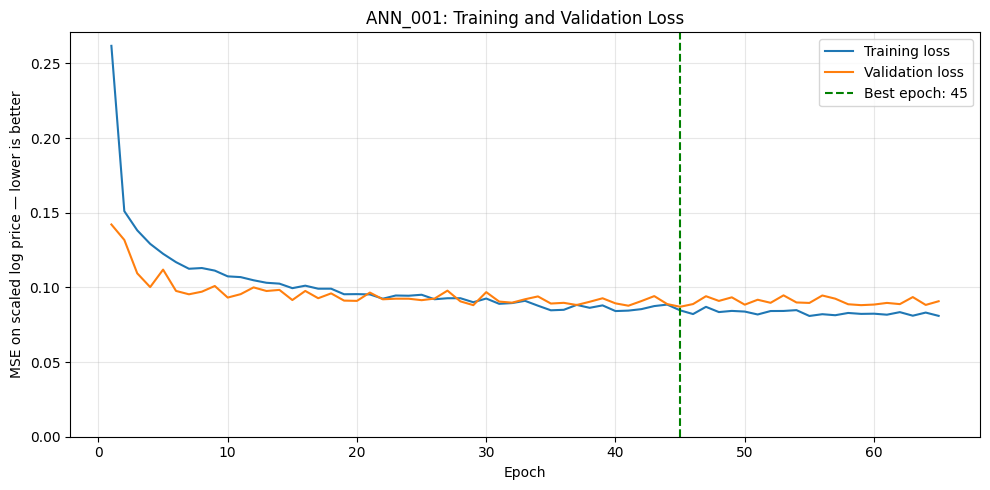

Best epoch: 45
Lowest validation loss: 0.087012


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
from google.colab import files

training_loss = ann_history.history["loss"]
validation_loss = ann_history.history["val_loss"]

epochs = range(1, len(training_loss) + 1)
best_epoch = int(np.argmin(validation_loss) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs, training_loss,
    color="tab:blue", label="Training loss"
)

plt.plot(
    epochs, validation_loss,
    color="tab:orange", label="Validation loss"
)

plt.axvline(
    best_epoch, color="green", linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.title("ANN_001: Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE on scaled log price — lower is better")
plt.ylim(bottom=0)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plot_path = "/content/ann_001_learning_curve.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Best epoch:", best_epoch)
print("Lowest validation loss:", round(min(validation_loss), 6))

files.download(plot_path)

In [ ]:
from itertools import product

optimizers = ["Adam", "RMSprop", "SGD"]

learning_rates = [0.001, 0.0001, 0.01]

loss_functions = ["MSE", "Huber"]
price_targets = ["Log price", "Raw price"]

combinations = list(product(
    optimizers,
    learning_rates,
    loss_functions,
    price_targets
))

experiment_plan = pd.DataFrame(
    combinations,
    columns=["Optimizer", "Learning rate", "Loss", "Price target"]
)

experiment_plan.insert(
    0,
    "Experiment",
    [
        f"ANN_{number:03d}"
        for number in range(1, len(experiment_plan) + 1)
    ]
)

experiment_plan["Status"] = "Pending"

experiment_plan.loc[
    experiment_plan["Experiment"].isin(
        experiment_results["Experiment"]
    ),
    "Status"
] = "Completed"

experiment_plan.to_csv(
    "/content/ann_experiment_plan.csv",
    index=False
)

print("Total experiments:", len(experiment_plan))
print("Completed:", (experiment_plan["Status"] == "Completed").sum())
print("Remaining:", (experiment_plan["Status"] == "Pending").sum())

display(experiment_plan)

Total experiments: 36
Completed: 1
Remaining: 35


,Experiment,Optimizer,Learning rate,Loss,Price target,Status
0,ANN_001,Adam,0.0010,MSE,Log price,Completed
1,ANN_002,Adam,0.0010,MSE,Raw price,Pending
2,ANN_003,Adam,0.0010,Huber,Log price,Pending
3,ANN_004,Adam,0.0010,Huber,Raw price,Pending
4,ANN_005,Adam,0.0001,MSE,Log price,Pending
5,ANN_006,Adam,0.0001,MSE,Raw price,Pending
6,ANN_007,Adam,0.0001,Huber,Log price,Pending
7,ANN_008,Adam,0.0001,Huber,Raw price,Pending
8,ANN_009,Adam,0.0100,MSE,Log price,Pending
9,ANN_010,Adam,0.0100,MSE,Raw price,Pending


In [ ]:
experiment_dir = backup_dir / "experiments"
experiment_dir.mkdir(parents=True, exist_ok=True)

if "Status" not in experiment_results.columns:
    experiment_results["Status"] = "Completed"

experiment_results.loc[
    experiment_results["Experiment"] == "ANN_001",
    "Model file"
] = "ann_001.keras"

experiment_plan["Status"] = experiment_plan["Experiment"].map(
    experiment_results.set_index("Experiment")["Status"]
).fillna("Pending")


def run_experiment(config):
    global experiment_results

    experiment_id = config["Experiment"]

    previous = experiment_results[
        (experiment_results["Experiment"] == experiment_id)
        & (experiment_results["Status"] == "Completed")
    ]

    if not previous.empty:
        print(f"{experiment_id} is already completed.")
        return previous.iloc[-1].to_dict()

    result = dict(config)
    result.update({
        "Target scaling": "StandardScaler",
        "Batch size": 32,
        "Random seed": SEED,
        "Status": "Failed",
        "Error": ""
    })

    print(
        f"Running {experiment_id}: "
        f"{config['Optimizer']}, "
        f"learning rate={config['Learning rate']}, "
        f"{config['Loss']}, {config['Price target']}"
    )

    try:
        use_log = config["Price target"] == "Log price"

        if use_log:
            train_target = y_train_log_scaled
            val_target = y_val_log_scaled
            target_scaler = log_target_scaler
        else:
            train_target = y_train_raw_scaled
            val_target = y_val_raw_scaled
            target_scaler = raw_target_scaler

        tf.keras.backend.clear_session()
        model = build_ann()

        optimizer_classes = {
            "Adam": tf.keras.optimizers.Adam,
            "RMSprop": tf.keras.optimizers.RMSprop,
            "SGD": tf.keras.optimizers.SGD
        }

        optimizer = optimizer_classes[config["Optimizer"]](
            learning_rate=float(config["Learning rate"])
        )

        if config["Loss"] == "MSE":
            loss_function = tf.keras.losses.MeanSquaredError()
        else:
            loss_function = tf.keras.losses.Huber(delta=1.0)

        model.compile(
            optimizer=optimizer,
            loss=loss_function,
            jit_compile=False
        )

        early_stop = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=20,
            restore_best_weights=True
        )

        history = model.fit(
            x={"brand": X_train_brand, "other": X_train_other},
            y=train_target,
            validation_data=(
                {"brand": X_val_brand, "other": X_val_other},
                val_target
            ),
            epochs=200,
            batch_size=32,
            shuffle=True,
            callbacks=[
                early_stop,
                tf.keras.callbacks.TerminateOnNaN()
            ],
            verbose=0
        )

        history_df = pd.DataFrame(history.history)
        history_df.index += 1
        history_df.to_csv(
            experiment_dir / f"{experiment_id}_history.csv",
            index_label="epoch"
        )

        result["Epochs completed"] = len(history_df)

        if not np.isfinite(
            history_df[["loss", "val_loss"]].to_numpy()
        ).all():
            raise FloatingPointError(
                "Training produced an invalid or infinite loss."
            )

        result["Best epoch"] = int(history_df["val_loss"].idxmin())
        result["Best validation loss"] = history_df["val_loss"].min()

        scaled_predictions = model.predict(
            {"brand": X_val_brand, "other": X_val_other},
            verbose=0
        )

        target_predictions = target_scaler.inverse_transform(
            scaled_predictions
        ).ravel().astype("float64")

        with np.errstate(over="raise", invalid="raise"):
            price_predictions = (
                np.exp(target_predictions)
                if use_log else target_predictions
            )

            if not np.isfinite(price_predictions).all():
                raise FloatingPointError(
                    "Predictions contain invalid or infinite values."
                )

            if np.all(price_predictions > 0):
                log_predictions = (
                    target_predictions
                    if use_log else np.log(price_predictions)
                )
                log_r2 = r2_score(y_val_log, log_predictions)
            else:
                log_r2 = np.nan

            result.update({
                "MAE (₹)": mean_absolute_error(
                    y_val, price_predictions
                ),
                "RMSE (₹)": np.sqrt(mean_squared_error(
                    y_val, price_predictions
                )),
                "R2 (raw price)": r2_score(
                    y_val, price_predictions
                ),
                "MAPE (%)": mean_absolute_percentage_error(
                    y_val, price_predictions
                ) * 100,
                "R2 (log price)": log_r2,
                "Non-positive predictions": int(
                    np.sum(price_predictions <= 0)
                )
            })

        model.save(str(experiment_dir / f"{experiment_id}.keras"))

        result["Model file"] = f"experiments/{experiment_id}.keras"
        result["Status"] = "Completed"

    except Exception as error:
        result["Status"] = "Failed"
        result["Error"] = f"{type(error).__name__}: {error}"
        print(f"{experiment_id} failed: {result['Error']}")

    experiment_results = pd.concat(
        [
            experiment_results[
                experiment_results["Experiment"] != experiment_id
            ],
            pd.DataFrame([result])
        ],
        ignore_index=True
    ).sort_values("Experiment").reset_index(drop=True)

    experiment_plan.loc[
        experiment_plan["Experiment"] == experiment_id,
        "Status"
    ] = result["Status"]

    experiment_results.to_csv(
        backup_dir / "experiment_results.csv",
        index=False
    )

    experiment_plan.to_csv(
        backup_dir / "experiment_plan.csv",
        index=False
    )

    print(f"{experiment_id}: {result['Status']}")
    return result


print("Experiment function is ready.")

Experiment function is ready.


In [ ]:
optimizer_configs = experiment_plan[
    np.isclose(experiment_plan["Learning rate"], 0.001)
    & (experiment_plan["Loss"] == "MSE")
    & (experiment_plan["Price target"] == "Log price")
].copy()

for _, config in optimizer_configs.iterrows():
    run_experiment(config)

optimizer_comparison = experiment_results[
    experiment_results["Experiment"].isin(
        optimizer_configs["Experiment"]
    )
][[
    "Optimizer",
    "MAE (₹)",
    "RMSE (₹)",
    "R2 (raw price)",
    "MAPE (%)",
    "R2 (log price)",
    "Status"
]].sort_values("MAE (₹)").reset_index(drop=True)

display(optimizer_comparison.round(4))

optimizer_comparison.to_csv(
    backup_dir / "optimizer_comparison.csv",
    index=False
)

zip_path = shutil.make_archive(
    "/content/used_car_optimizer_comparison",
    "zip",
    root_dir=str(backup_dir)
)
files.download(zip_path)

ANN_001 is already completed.
Running ANN_013: RMSprop, learning rate=0.001, MSE, Log price
ANN_013: Completed
Running ANN_025: SGD, learning rate=0.001, MSE, Log price
ANN_025: Completed


,Optimizer,MAE (₹),RMSE (₹),R2 (raw price),MAPE (%),R2 (log price),Status
0,RMSprop,76239.4359,160909.2089,0.8694,16.4943,0.9094,Completed
1,Adam,78862.0625,168834.5898,0.8562,16.9776,0.9102,Completed
2,SGD,85085.7405,165305.0069,0.8622,19.0735,0.8838,Completed


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
selected_optimizer = "RMSprop"

learning_rate_configs = experiment_plan[
    (experiment_plan["Optimizer"] == selected_optimizer)
    & (experiment_plan["Loss"] == "MSE")
    & (experiment_plan["Price target"] == "Log price")
].copy()

for _, config in learning_rate_configs.iterrows():
    run_experiment(config)

learning_rate_comparison = experiment_results[
    experiment_results["Experiment"].isin(
        learning_rate_configs["Experiment"]
    )
][[
    "Optimizer",
    "Learning rate",
    "MAE (₹)",
    "RMSE (₹)",
    "R2 (raw price)",
    "MAPE (%)",
    "R2 (log price)",
    "Status"
]].sort_values("MAE (₹)").reset_index(drop=True)

display(learning_rate_comparison.round(4))

learning_rate_comparison.to_csv(
    backup_dir / "learning_rate_comparison.csv",
    index=False
)

zip_path = shutil.make_archive(
    "/content/used_car_learning_rate_comparison",
    "zip",
    root_dir=str(backup_dir)
)
files.download(zip_path)

ANN_013 is already completed.
Running ANN_017: RMSprop, learning rate=0.0001, MSE, Log price
ANN_017: Completed
Running ANN_021: RMSprop, learning rate=0.01, MSE, Log price
ANN_021: Completed


,Optimizer,Learning rate,MAE (₹),RMSE (₹),R2 (raw price),MAPE (%),R2 (log price),Status
0,RMSprop,0.0010,76239.4359,160909.2089,0.8694,16.4943,0.9094,Completed
1,RMSprop,0.0001,79854.7791,174447.2078,0.8465,17.4223,0.9055,Completed
2,RMSprop,0.0100,81818.1887,172364.2628,0.8501,17.7588,0.8990,Completed


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
selected_optimizer = "RMSprop"
selected_learning_rate = 0.001

loss_configs = experiment_plan[
    (experiment_plan["Optimizer"] == selected_optimizer)
    & np.isclose(
        experiment_plan["Learning rate"],
        selected_learning_rate
    )
    & (experiment_plan["Price target"] == "Log price")
].copy()

for _, config in loss_configs.iterrows():
    run_experiment(config)

loss_comparison = experiment_results[
    experiment_results["Experiment"].isin(
        loss_configs["Experiment"]
    )
][[
    "Optimizer",
    "Learning rate",
    "Loss",
    "MAE (₹)",
    "RMSE (₹)",
    "R2 (raw price)",
    "MAPE (%)",
    "R2 (log price)",
    "Status"
]].sort_values("MAE (₹)").reset_index(drop=True)

display(loss_comparison.round(4))

loss_comparison.to_csv(
    backup_dir / "loss_comparison.csv",
    index=False
)

zip_path = shutil.make_archive(
    "/content/used_car_loss_comparison",
    "zip",
    root_dir=str(backup_dir)
)
files.download(zip_path)

ANN_013 is already completed.
Running ANN_015: RMSprop, learning rate=0.001, Huber, Log price
ANN_015: Completed


,Optimizer,Learning rate,Loss,MAE (₹),RMSE (₹),R2 (raw price),MAPE (%),R2 (log price),Status
0,RMSprop,0.001,MSE,76239.4359,160909.2089,0.8694,16.4943,0.9094,Completed
1,RMSprop,0.001,Huber,77196.4951,159195.4350,0.8722,16.6318,0.9085,Completed


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
selected_optimizer = "RMSprop"
selected_learning_rate = 0.001
selected_loss = "MSE"

target_configs = experiment_plan[
    (experiment_plan["Optimizer"] == selected_optimizer)
    & np.isclose(
        experiment_plan["Learning rate"],
        selected_learning_rate
    )
    & (experiment_plan["Loss"] == selected_loss)
].copy()

for _, config in target_configs.iterrows():
    run_experiment(config)

target_comparison = experiment_results[
    experiment_results["Experiment"].isin(
        target_configs["Experiment"]
    )
][[
    "Price target",
    "MAE (₹)",
    "RMSE (₹)",
    "R2 (raw price)",
    "MAPE (%)",
    "R2 (log price)",
    "Non-positive predictions",
    "Status"
]].sort_values("MAE (₹)").reset_index(drop=True)

display(target_comparison.round(4))

target_comparison.to_csv(
    backup_dir / "target_comparison.csv",
    index=False
)

zip_path = shutil.make_archive(
    "/content/used_car_target_comparison",
    "zip",
    root_dir=str(backup_dir)
)
files.download(zip_path)

ANN_013 is already completed.
Running ANN_014: RMSprop, learning rate=0.001, MSE, Raw price
ANN_014: Completed


,Price target,MAE (₹),RMSE (₹),R2 (raw price),MAPE (%),R2 (log price),Non-positive predictions,Status
0,Log price,76239.4359,160909.2089,0.8694,16.4943,0.9094,0.0,Completed
1,Raw price,80682.1319,159661.6374,0.8714,19.7179,NaN,6.0,Completed


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
summary_columns = [
    "Experiment", "Optimizer", "Learning rate", "Loss",
    "Price target", "MAE (₹)", "RMSE (₹)",
    "R2 (raw price)", "MAPE (%)", "R2 (log price)", "Status"
]

validation_summary = (
    experiment_results[summary_columns]
    .sort_values("MAE (₹)", na_position="last")
    .reset_index(drop=True)
)

display(validation_summary.round(4))


eligible_models = experiment_results[
    (experiment_results["Status"] == "Completed")
    & np.isfinite(experiment_results["MAE (₹)"])
    & np.isfinite(experiment_results["R2 (log price)"])
    & (experiment_results["R2 (log price)"] >= 0.85)
].copy()

if eligible_models.empty:
    raise ValueError(
        "No completed experiment meets the validation log-price R² requirement."
    )

best_row = eligible_models.sort_values("MAE (₹)").iloc[0]

selected_model_path = backup_dir / best_row["Model file"]

selected_ann_model = tf.keras.models.load_model(
    str(selected_model_path),
    compile=False
)


selected_uses_log = best_row["Price target"] == "Log price"

selected_target_scaler = (
    log_target_scaler if selected_uses_log else raw_target_scaler
)


validation_summary.to_csv(
    backup_dir / "validation_experiment_summary.csv",
    index=False
)

best_row.to_frame().T.to_csv(
    backup_dir / "selected_ann_configuration.csv",
    index=False
)

print(f"Selected experiment: {best_row['Experiment']}")
print(f"Validation MAE: ₹{best_row['MAE (₹)']:,.2f}")
print(f"Validation log-price R²: {best_row['R2 (log price)']:.4f}")


zip_path = shutil.make_archive(
    "/content/used_car_selected_ann_backup",
    "zip",
    root_dir=str(backup_dir)
)

files.download(zip_path)

,Experiment,Optimizer,Learning rate,Loss,Price target,MAE (₹),RMSE (₹),R2 (raw price),MAPE (%),R2 (log price),Status
0,ANN_013,RMSprop,0.0010,MSE,Log price,76239.4359,160909.2089,0.8694,16.4943,0.9094,Completed
1,ANN_015,RMSprop,0.0010,Huber,Log price,77196.4951,159195.4350,0.8722,16.6318,0.9085,Completed
2,ANN_001,Adam,0.0010,MSE,Log price,78862.0625,168834.5898,0.8562,16.9776,0.9102,Completed
3,ANN_017,RMSprop,0.0001,MSE,Log price,79854.7791,174447.2078,0.8465,17.4223,0.9055,Completed
4,ANN_014,RMSprop,0.0010,MSE,Raw price,80682.1319,159661.6374,0.8714,19.7179,NaN,Completed
5,ANN_021,RMSprop,0.0100,MSE,Log price,81818.1887,172364.2628,0.8501,17.7588,0.8990,Completed
6,ANN_025,SGD,0.0010,MSE,Log price,85085.7405,165305.0069,0.8622,19.0735,0.8838,Completed


Selected experiment: ANN_013
Validation MAE: ₹76,239.44
Validation log-price R²: 0.9094


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
scratch_rng = np.random.default_rng(SEED)

scratch_embedding_dim = 8
scratch_hidden_1 = 64
scratch_hidden_2 = 32

scratch_input_dim = (
    X_train_other.shape[1] + scratch_embedding_dim
)

scratch_params = {
    "embedding": scratch_rng.normal(
        0.0, 0.05,
        size=(num_brand_ids, scratch_embedding_dim)
    ),

    "W1": scratch_rng.normal(
        0.0, np.sqrt(2.0 / scratch_input_dim),
        size=(scratch_input_dim, scratch_hidden_1)
    ),
    "b1": np.zeros((1, scratch_hidden_1)),

    "W2": scratch_rng.normal(
        0.0, np.sqrt(2.0 / scratch_hidden_1),
        size=(scratch_hidden_1, scratch_hidden_2)
    ),
    "b2": np.zeros((1, scratch_hidden_2)),

    "W3": scratch_rng.normal(
        0.0, np.sqrt(1.0 / scratch_hidden_2),
        size=(scratch_hidden_2, 1)
    ),
    "b3": np.zeros((1, 1))
}

scratch_parameter_table = pd.DataFrame([
    {
        "Parameter": name,
        "Shape": values.shape,
        "Count": values.size
    }
    for name, values in scratch_params.items()
])

display(scratch_parameter_table)

print(
    "Total trainable parameters:",
    sum(values.size for values in scratch_params.values())
)

,Parameter,Shape,Count
0,embedding,"(22, 8)",176
1,W1,"(30, 64)",1920
2,b1,"(1, 64)",64
3,W2,"(64, 32)",2048
4,b2,"(1, 32)",32
5,W3,"(32, 1)",32
6,b3,"(1, 1)",1


Total trainable parameters: 4273


In [ ]:
def scratch_forward(
    brand_ids, other_features, params,
    training=False, dropout_rate=0.10, rng=None
):
    if not 0 <= dropout_rate < 1:
        raise ValueError("dropout_rate must satisfy 0 <= rate < 1.")

    if training and rng is None:
        raise ValueError("Provide a random generator when training=True.")

    ids = np.asarray(brand_ids).reshape(-1)
    brand_vectors = params["embedding"][ids]

    inputs = np.hstack([other_features, brand_vectors])

    z1 = inputs @ params["W1"] + params["b1"]
    a1 = np.maximum(0, z1)

    mask1 = np.ones_like(a1)

    if training:
        mask1 = (
            (rng.random(a1.shape) >= dropout_rate)
            / (1 - dropout_rate)
        )

    h1 = a1 * mask1

    z2 = h1 @ params["W2"] + params["b2"]
    a2 = np.maximum(0, z2)

    mask2 = np.ones_like(a2)

    if training:
        mask2 = (
            (rng.random(a2.shape) >= dropout_rate)
            / (1 - dropout_rate)
        )

    h2 = a2 * mask2

    predictions = h2 @ params["W3"] + params["b3"]

    cache = {
        "ids": ids,
        "inputs": inputs,
        "z1": z1,
        "h1": h1,
        "mask1": mask1,
        "z2": z2,
        "h2": h2,
        "mask2": mask2
    }

    return predictions, cache


scratch_demo_predictions, scratch_demo_cache = scratch_forward(
    X_train_brand[:5],
    X_train_other[:5],
    scratch_params,
    training=False
)

print("Prediction shape:", scratch_demo_predictions.shape)
print("All values finite:", np.isfinite(scratch_demo_predictions).all())

display(pd.DataFrame({
    "Initial output (scaled log price)":
        scratch_demo_predictions.ravel()
}))

Prediction shape: (5, 1)
All values finite: True


,Initial output (scaled log price)
0,-2.168151
1,-0.360219
2,-0.701737
3,-0.256805
4,-0.459069


In [ ]:
def scratch_loss_and_gradients(params, predictions, targets, cache):
    targets = np.asarray(
        targets, dtype="float64"
    ).reshape(-1, 1)

    if predictions.shape != targets.shape:
        raise ValueError(
            "Predictions and targets must have matching shapes."
        )

    errors = predictions - targets
    loss = np.mean(errors ** 2)

    d_predictions = 2.0 * errors / len(targets)

    grads = {}

    grads["W3"] = cache["h2"].T @ d_predictions
    grads["b3"] = d_predictions.sum(axis=0, keepdims=True)

    d_h2 = d_predictions @ params["W3"].T
    d_z2 = d_h2 * cache["mask2"] * (cache["z2"] > 0)

    grads["W2"] = cache["h1"].T @ d_z2
    grads["b2"] = d_z2.sum(axis=0, keepdims=True)

    d_h1 = d_z2 @ params["W2"].T
    d_z1 = d_h1 * cache["mask1"] * (cache["z1"] > 0)

    grads["W1"] = cache["inputs"].T @ d_z1
    grads["b1"] = d_z1.sum(axis=0, keepdims=True)

    d_inputs = d_z1 @ params["W1"].T

    embedding_dim = params["embedding"].shape[1]
    d_embedding = d_inputs[:, -embedding_dim:]

    grads["embedding"] = np.zeros_like(params["embedding"])

    np.add.at(
        grads["embedding"],
        cache["ids"],
        d_embedding
    )

    return float(loss), grads


scratch_demo_predictions, scratch_demo_cache = scratch_forward(
    X_train_brand[:5],
    X_train_other[:5],
    scratch_params,
    training=False
)

scratch_demo_loss, scratch_demo_grads = scratch_loss_and_gradients(
    scratch_params,
    scratch_demo_predictions,
    y_train_log_scaled[:5],
    scratch_demo_cache
)

print("Initial MSE:", round(scratch_demo_loss, 6))

print(
    "All gradient shapes correct:",
    all(
        scratch_demo_grads[name].shape == values.shape
        for name, values in scratch_params.items()
    )
)

print(
    "All gradients finite:",
    all(
        np.isfinite(values).all()
        for values in scratch_demo_grads.values()
    )
)

Initial MSE: 3.750189
All gradient shapes correct: True
All gradients finite: True


In [ ]:
def scratch_rmsprop_step(
    params, grads, rms_state,
    learning_rate=0.001, rho=0.9, epsilon=1e-7
):
    for name in params:

        rms_state[name] = (
            rho * rms_state[name]
            + (1.0 - rho) * grads[name] ** 2
        )

        params[name] -= (
            learning_rate * grads[name]
            / np.sqrt(rms_state[name] + epsilon)
        )


scratch_demo_params = {
    name: values.copy()
    for name, values in scratch_params.items()
}

scratch_demo_rms_state = {
    name: np.zeros_like(values)
    for name, values in scratch_demo_params.items()
}

scratch_rmsprop_step(
    scratch_demo_params,
    scratch_demo_grads,
    scratch_demo_rms_state
)

print("RMSprop update completed.")

print(
    "All updated parameters finite:",
    all(
        np.isfinite(values).all()
        for values in scratch_demo_params.values()
    )
)

RMSprop update completed.
All updated parameters finite: True


In [ ]:
scratch_train_brand = np.asarray(X_train_brand).reshape(-1)
scratch_val_brand = np.asarray(X_val_brand).reshape(-1)

scratch_train_other = np.asarray(X_train_other, dtype="float64")
scratch_val_other = np.asarray(X_val_other, dtype="float64")

scratch_train_target = np.asarray(
    y_train_log_scaled, dtype="float64"
).reshape(-1, 1)

scratch_val_target = np.asarray(
    y_val_log_scaled, dtype="float64"
).reshape(-1, 1)

scratch_fit_params = {
    name: values.copy()
    for name, values in scratch_params.items()
}

scratch_rms_state = {
    name: np.zeros_like(values)
    for name, values in scratch_fit_params.items()
}

scratch_training_rng = np.random.default_rng(SEED)

scratch_batch_size = 32
scratch_patience = 20
scratch_n_train = len(scratch_train_target)

scratch_history_rows = []
scratch_best_val_loss = np.inf
scratch_wait = 0

for epoch in range(1, 201):

    order = scratch_training_rng.permutation(scratch_n_train)
    total_train_loss = 0.0

    for start in range(0, scratch_n_train, scratch_batch_size):
        batch_ids = order[start:start + scratch_batch_size]

        batch_predictions, cache = scratch_forward(
            scratch_train_brand[batch_ids],
            scratch_train_other[batch_ids],
            scratch_fit_params,
            training=True,
            dropout_rate=0.10,
            rng=scratch_training_rng
        )

        batch_loss, grads = scratch_loss_and_gradients(
            scratch_fit_params,
            batch_predictions,
            scratch_train_target[batch_ids],
            cache
        )

        if (
            not np.isfinite(batch_loss)
            or not all(np.isfinite(g).all() for g in grads.values())
        ):
            raise FloatingPointError(
                "Training produced a non-finite loss or gradient."
            )

        scratch_rmsprop_step(
            scratch_fit_params,
            grads,
            scratch_rms_state,
            learning_rate=0.001
        )

        total_train_loss += batch_loss * len(batch_ids)

    val_predictions, _ = scratch_forward(
        scratch_val_brand,
        scratch_val_other,
        scratch_fit_params,
        training=False
    )

    train_loss = total_train_loss / scratch_n_train

    val_loss = float(np.mean(
        (val_predictions - scratch_val_target) ** 2
    ))

    if not np.isfinite(val_loss):
        raise FloatingPointError("Validation loss is not finite.")

    scratch_history_rows.append({
        "epoch": epoch,
        "loss": train_loss,
        "val_loss": val_loss
    })

    if val_loss < scratch_best_val_loss:
        scratch_best_val_loss = val_loss
        scratch_best_epoch = epoch

        scratch_best_params = {
            name: values.copy()
            for name, values in scratch_fit_params.items()
        }

        scratch_wait = 0
    else:
        scratch_wait += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"Training MSE: {train_loss:.6f} | "
            f"Validation MSE: {val_loss:.6f}"
        )

    if scratch_wait >= scratch_patience:
        print(f"Early stopping at epoch {epoch}.")
        break

scratch_trained_params = scratch_best_params

scratch_history = pd.DataFrame(scratch_history_rows)

np.savez(
    backup_dir / "scratch_ann_best_weights.npz",
    **scratch_trained_params
)

scratch_history.to_csv(
    backup_dir / "scratch_training_history.csv",
    index=False
)

print("\nTraining completed.")
print("Epochs completed:", len(scratch_history))
print("Best epoch:", scratch_best_epoch)
print(f"Best validation MSE: {scratch_best_val_loss:.6f}")

zip_path = shutil.make_archive(
    "/content/used_car_scratch_training_backup",
    "zip",
    root_dir=str(backup_dir)
)
files.download(zip_path)

Epoch   1 | Training MSE: 0.391072 | Validation MSE: 0.125591
Epoch  10 | Training MSE: 0.114338 | Validation MSE: 0.104414
Epoch  20 | Training MSE: 0.103057 | Validation MSE: 0.088020
Epoch  30 | Training MSE: 0.097293 | Validation MSE: 0.092683
Epoch  40 | Training MSE: 0.093898 | Validation MSE: 0.092660
Epoch  50 | Training MSE: 0.088240 | Validation MSE: 0.087711
Epoch  60 | Training MSE: 0.086234 | Validation MSE: 0.086273
Epoch  70 | Training MSE: 0.086150 | Validation MSE: 0.084536
Epoch  80 | Training MSE: 0.083042 | Validation MSE: 0.087079
Epoch  90 | Training MSE: 0.082547 | Validation MSE: 0.093533
Early stopping at epoch 90.

Training completed.
Epochs completed: 90
Best epoch: 70
Best validation MSE: 0.084536


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

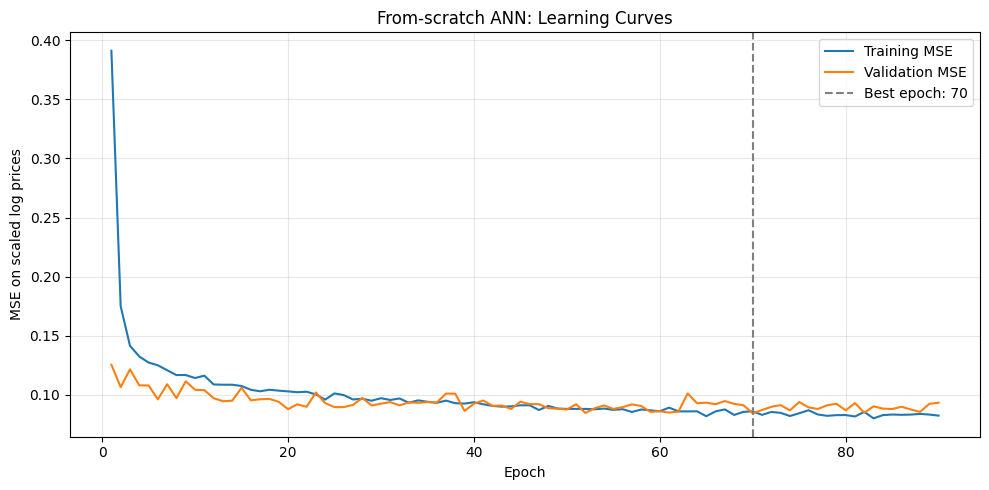

,Model,MAE (₹),RMSE (₹),R2 (raw price),MAPE (%),R2 (log price)
0,NumPy ANN,77768.1971,176668.6896,0.8425,16.5058,0.9127


Learning curves and validation results saved.


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    scratch_history["epoch"],
    scratch_history["loss"],
    label="Training MSE"
)

plt.plot(
    scratch_history["epoch"],
    scratch_history["val_loss"],
    label="Validation MSE"
)

plt.axvline(
    scratch_best_epoch,
    color="gray",
    linestyle="--",
    label=f"Best epoch: {scratch_best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("MSE on scaled log prices")
plt.title("From-scratch ANN: Learning Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    backup_dir / "scratch_learning_curves.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

scratch_val_scaled_predictions, _ = scratch_forward(
    scratch_val_brand,
    scratch_val_other,
    scratch_trained_params,
    training=False
)

scratch_val_log_predictions = (
    log_target_scaler.inverse_transform(
        scratch_val_scaled_predictions
    ).ravel().astype("float64")
)

with np.errstate(over="raise", invalid="raise"):
    scratch_val_price_predictions = np.exp(
        scratch_val_log_predictions
    )

if not np.isfinite(scratch_val_price_predictions).all():
    raise FloatingPointError("Validation predictions are not finite.")

actual_val_prices = np.asarray(y_val, dtype="float64").ravel()
actual_val_log = np.asarray(y_val_log, dtype="float64").ravel()

scratch_validation_results = pd.DataFrame([{
    "Model": "NumPy ANN",
    "MAE (₹)": mean_absolute_error(
        actual_val_prices, scratch_val_price_predictions
    ),
    "RMSE (₹)": np.sqrt(mean_squared_error(
        actual_val_prices, scratch_val_price_predictions
    )),
    "R2 (raw price)": r2_score(
        actual_val_prices, scratch_val_price_predictions
    ),
    "MAPE (%)": mean_absolute_percentage_error(
        actual_val_prices, scratch_val_price_predictions
    ) * 100,
    "R2 (log price)": r2_score(
        actual_val_log, scratch_val_log_predictions
    )
}])

display(scratch_validation_results.round(4))

scratch_validation_results.to_csv(
    backup_dir / "scratch_validation_results.csv",
    index=False
)

print("Learning curves and validation results saved.")

In [ ]:
metric_columns = [
    "MAE (₹)",
    "RMSE (₹)",
    "R2 (raw price)",
    "MAPE (%)",
    "R2 (log price)"
]

keras_validation_row = {
    "Model": f"Keras ANN ({best_row['Experiment']})",
    **best_row[metric_columns].to_dict()
}

ann_validation_comparison = pd.concat(
    [
        pd.DataFrame([keras_validation_row]),
        scratch_validation_results[["Model"] + metric_columns]
    ],
    ignore_index=True
).sort_values("MAE (₹)").reset_index(drop=True)

display(ann_validation_comparison.round(4))

ann_validation_comparison.to_csv(
    backup_dir / "keras_vs_numpy_validation.csv",
    index=False
)

print("Validation comparison saved.")
print("Primary model: selected_ann_model — Keras ANN")
print("From-scratch model: scratch_trained_params — NumPy ANN")

,Model,MAE (₹),RMSE (₹),R2 (raw price),MAPE (%),R2 (log price)
0,Keras ANN (ANN_013),76239.4359,160909.2089,0.8694,16.4943,0.9094
1,NumPy ANN,77768.1971,176668.6896,0.8425,16.5058,0.9127


Validation comparison saved.
Primary model: selected_ann_model — Keras ANN
From-scratch model: scratch_trained_params — NumPy ANN


In [ ]:
test_results_file = backup_dir / "final_test_results.csv"
test_predictions_file = backup_dir / "final_test_predictions.csv"

if test_results_file.exists() and test_predictions_file.exists():

    final_test_results = pd.read_csv(test_results_file)
    final_test_predictions = pd.read_csv(
        test_predictions_file,
        index_col="row_id"
    )

    print("Loaded existing final test results.")

else:
    actual_test_prices = np.asarray(
        y_test, dtype="float64"
    ).ravel()

    if (
        not np.isfinite(actual_test_prices).all()
        or np.any(actual_test_prices <= 0)
    ):
        raise ValueError("Actual test prices must be finite and positive.")

    if hasattr(y_test, "index"):
        if not X_test.index.equals(y_test.index):
            raise ValueError("Test features and targets are not aligned.")

    baseline_test_prices = np.asarray(
        baseline_model.predict(X_test_baseline),
        dtype="float64"
    ).ravel()

    keras_test_scaled = selected_ann_model.predict(
        {"brand": X_test_brand, "other": X_test_other},
        verbose=0
    )

    keras_test_target = selected_target_scaler.inverse_transform(
        keras_test_scaled
    ).ravel().astype("float64")

    numpy_test_scaled, _ = scratch_forward(
        np.asarray(X_test_brand).reshape(-1),
        np.asarray(X_test_other, dtype="float64"),
        scratch_trained_params,
        training=False
    )

    numpy_test_log = log_target_scaler.inverse_transform(
        numpy_test_scaled
    ).ravel().astype("float64")

    with np.errstate(over="raise", invalid="raise"):
        keras_test_prices = (
            np.exp(keras_test_target)
            if selected_uses_log
            else keras_test_target
        )

        numpy_test_prices = np.exp(numpy_test_log)

    model_predictions = {
        "Linear regression": baseline_test_prices,
        "Keras ANN": keras_test_prices,
        "NumPy ANN": numpy_test_prices
    }

    test_rows = []

    for model_name, predictions in model_predictions.items():

        if predictions.shape != actual_test_prices.shape:
            raise ValueError(f"{model_name}: prediction shape mismatch.")

        if not np.isfinite(predictions).all():
            raise FloatingPointError(
                f"{model_name}: predictions contain non-finite values."
            )

        non_positive = int(np.sum(predictions <= 0))

        log_r2 = (
            r2_score(
                np.log(actual_test_prices),
                np.log(predictions)
            )
            if non_positive == 0
            else np.nan
        )

        test_rows.append({
            "Model": model_name,
            "MAE (₹)": mean_absolute_error(
                actual_test_prices, predictions
            ),
            "RMSE (₹)": np.sqrt(mean_squared_error(
                actual_test_prices, predictions
            )),
            "R2 (raw price)": r2_score(
                actual_test_prices, predictions
            ),
            "MAPE (%)": mean_absolute_percentage_error(
                actual_test_prices, predictions
            ) * 100,
            "R2 (log price)": log_r2,
            "Non-positive predictions": non_positive
        })

    final_test_results = pd.DataFrame(test_rows)

    final_test_predictions = pd.DataFrame(
        {
            "Actual price (₹)": actual_test_prices,
            **model_predictions
        },
        index=X_test.index
    )

    final_test_results.to_csv(test_results_file, index=False)

    final_test_predictions.to_csv(
        test_predictions_file,
        index_label="row_id"
    )

    print("Final test evaluation completed and saved.")

display(final_test_results.round(4))

test_scores = final_test_results.set_index("Model")

print(
    "Keras ANN beats linear regression on test MAE:",
    test_scores.loc["Keras ANN", "MAE (₹)"]
    < test_scores.loc["Linear regression", "MAE (₹)"]
)

print(
    "Keras ANN test log-price R² is at least 0.85:",
    test_scores.loc["Keras ANN", "R2 (log price)"] >= 0.85
)

zip_path = shutil.make_archive(
    "/content/used_car_final_test_backup",
    "zip",
    root_dir=str(backup_dir)
)
files.download(zip_path)

Final test evaluation completed and saved.


,Model,MAE (₹),RMSE (₹),R2 (raw price),MAPE (%),R2 (log price),Non-positive predictions
0,Linear regression,139438.1756,269481.7365,0.7256,46.3390,NaN,63
1,Keras ANN,77564.6031,150234.3644,0.9147,16.9260,0.9085,0
2,NumPy ANN,78488.8483,160592.0753,0.9026,17.2563,0.9074,0


Keras ANN beats linear regression on test MAE: True
Keras ANN test log-price R² is at least 0.85: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

TEST ERRORS BY FUEL TYPE


,Fuel type,Cars,MAE (₹),RMSE (₹),Mean residual (₹),MAPE (%)
0,CNG,13,34312.32,51045.79,11494.49,12.83
1,Diesel,557,97779.01,189692.75,15380.05,16.89
2,LPG,4,49204.07,56625.66,42697.98,22.18
3,Petrol,465,54803.95,85019.79,5469.68,17.04



TEST ERRORS BY ACTUAL PRICE BAND


,Price band,Cars,MAE (₹),RMSE (₹),Mean residual (₹),MAPE (%)
0,Up to 3 lakh,358,35878.82,46535.18,-4087.97,22.03
1,>3 to 6 lakh,409,65817.76,83199.89,352.20,14.76
2,>6 to 10 lakh,212,99101.67,132978.69,34661.14,12.79
3,>10 lakh,60,330266.52,517933.34,90026.47,15.86


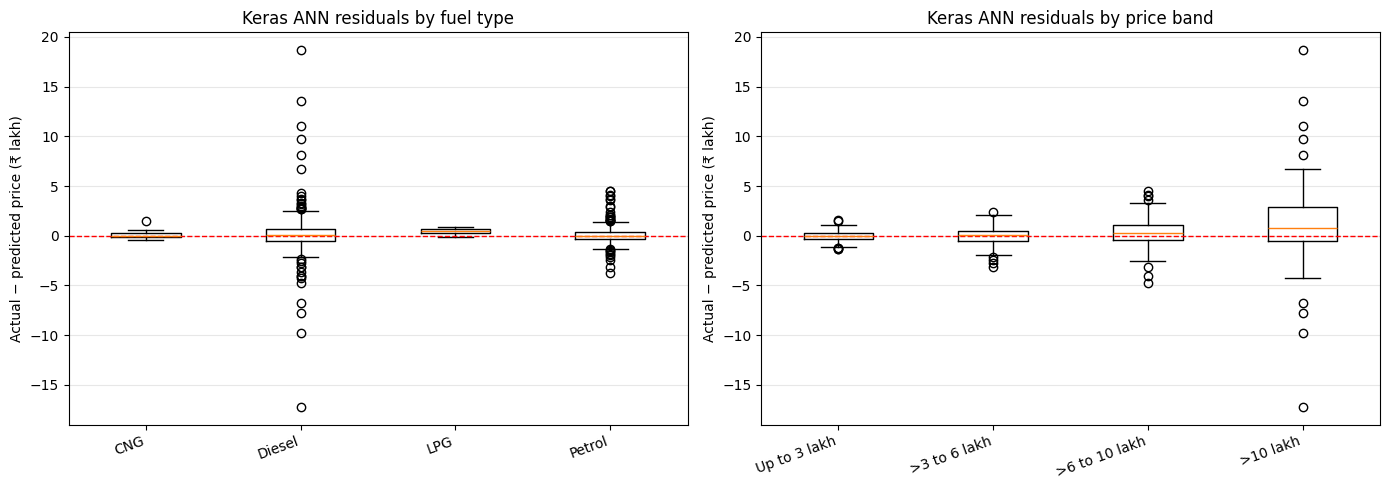

Residual analysis saved.


In [ ]:
residual_analysis = final_test_predictions[
    ["Actual price (₹)", "Keras ANN"]
].copy()

residual_analysis["Fuel type"] = (
    X_test.loc[residual_analysis.index, "fuel"]
    .astype("string")
    .fillna("Unknown")
)

residual_analysis["Residual (₹)"] = (
    residual_analysis["Actual price (₹)"]
    - residual_analysis["Keras ANN"]
)

residual_analysis["Price band"] = pd.cut(
    residual_analysis["Actual price (₹)"],
    bins=[0, 300000, 600000, 1000000, np.inf],
    labels=[
        "Up to 3 lakh",
        ">3 to 6 lakh",
        ">6 to 10 lakh",
        ">10 lakh"
    ],
    right=True,
    include_lowest=True
)

def summarize_residuals(group_column):
    rows = []

    for group_name, group in residual_analysis.groupby(
        group_column,
        observed=True,
        dropna=False
    ):
        errors = group["Residual (₹)"]
        actual = group["Actual price (₹)"]

        rows.append({
            group_column: group_name,
            "Cars": len(group),
            "MAE (₹)": errors.abs().mean(),
            "RMSE (₹)": np.sqrt((errors ** 2).mean()),
            "Mean residual (₹)": errors.mean(),
            "MAPE (%)": (errors.abs() / actual).mean() * 100
        })

    return pd.DataFrame(rows)


fuel_residual_summary = summarize_residuals("Fuel type")
price_band_residual_summary = summarize_residuals("Price band")

print("TEST ERRORS BY FUEL TYPE")
display(fuel_residual_summary.round(2))

print("\nTEST ERRORS BY ACTUAL PRICE BAND")
display(price_band_residual_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column in zip(axes, ["Fuel type", "Price band"]):
    groups = list(residual_analysis.groupby(
        column,
        observed=True,
        dropna=False
    ))

    values = [
        group["Residual (₹)"].to_numpy() / 100000
        for _, group in groups
    ]

    labels = [str(name) for name, _ in groups]

    ax.boxplot(values)
    ax.set_xticks(range(1, len(labels) + 1))
    ax.set_xticklabels(labels, rotation=20, ha="right")

    ax.axhline(0, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"Keras ANN residuals by {column.lower()}")
    ax.set_ylabel("Actual − predicted price (₹ lakh)")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    backup_dir / "residual_boxplots.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

residual_analysis.to_csv(
    backup_dir / "keras_test_residuals.csv",
    index_label="row_id"
)

fuel_residual_summary.to_csv(
    backup_dir / "residuals_by_fuel.csv",
    index=False
)

price_band_residual_summary.to_csv(
    backup_dir / "residuals_by_price_band.csv",
    index=False
)

print("Residual analysis saved.")

In [ ]:
def mc_dropout_predict(brand_ids, other_features, n_samples=50):

    if n_samples < 2:
        raise ValueError("Use at least two Monte Carlo samples.")

    inputs = {
        "brand": np.asarray(
            brand_ids, dtype="int32"
        ).reshape(-1, 1),

        "other": np.asarray(
            other_features, dtype="float32"
        )
    }

    def to_rupees(scaled_outputs):
        target_values = selected_target_scaler.inverse_transform(
            scaled_outputs
        ).ravel().astype("float64")

        with np.errstate(over="raise", invalid="raise"):
            prices = (
                np.exp(target_values)
                if selected_uses_log
                else target_values
            )

        if not np.isfinite(prices).all():
            raise FloatingPointError("Predictions are not finite.")

        return prices

    point_scaled = selected_ann_model(
        inputs, training=False
    ).numpy()

    point_prices = to_rupees(point_scaled)

    price_samples = np.empty(
        (len(inputs["brand"]), n_samples),
        dtype="float64"
    )

    for sample_number in range(n_samples):
        sampled_scaled = selected_ann_model(
            inputs, training=True
        ).numpy()

        price_samples[:, sample_number] = to_rupees(
            sampled_scaled
        )

    results = pd.DataFrame({
        "Predicted price (₹)": point_prices,
        "MC mean price (₹)": price_samples.mean(axis=1),
        "Low (₹)": np.percentile(price_samples, 5, axis=1),
        "High (₹)": np.percentile(price_samples, 95, axis=1)
    })

    results["Range width (₹)"] = (
        results["High (₹)"] - results["Low (₹)"]
    )

    return results, price_samples


mc_validation, mc_validation_samples = mc_dropout_predict(
    X_val_brand,
    X_val_other,
    n_samples=50
)

mc_validation.index = X_val.index

mc_validation.insert(
    0,
    "Actual price (₹)",
    np.asarray(y_val, dtype="float64").ravel()
)

mc_validation["Actual inside range"] = (
    (mc_validation["Actual price (₹)"] >= mc_validation["Low (₹)"])
    & (mc_validation["Actual price (₹)"] <= mc_validation["High (₹)"])
)

mc_validation_coverage = (
    mc_validation["Actual inside range"].mean() * 100
)

mc_preview = mc_validation[[
    "Actual price (₹)",
    "Predicted price (₹)",
    "Low (₹)",
    "High (₹)"
]].head(10) / 100000

mc_preview.columns = [
    "Actual (₹ lakh)",
    "Prediction (₹ lakh)",
    "Low (₹ lakh)",
    "High (₹ lakh)"
]

display(mc_preview.round(2))

print("Monte Carlo predictions per car:", mc_validation_samples.shape[1])

print(
    "Validation prices inside the MC range:",
    f"{mc_validation_coverage:.2f}%"
)

print(
    "Average range width:",
    f"₹{mc_validation['Range width (₹)'].mean():,.2f}"
)

mc_validation.to_csv(
    backup_dir / "mc_dropout_validation.csv",
    index_label="row_id"
)

np.save(
    backup_dir / "mc_dropout_validation_samples.npy",
    mc_validation_samples
)

print("Monte Carlo dropout results saved.")

,Actual (₹ lakh),Prediction (₹ lakh),Low (₹ lakh),High (₹ lakh)
5582,1.85,1.82,1.46,2.07
1097,1.90,2.20,1.89,2.63
2781,1.55,2.21,2.01,2.38
268,6.10,6.42,5.77,7.12
1092,1.00,1.00,0.82,1.19
3479,4.50,3.66,3.38,3.98
5660,2.95,3.22,2.94,3.43
1511,8.20,5.28,4.70,6.03
1244,3.50,3.32,3.16,3.73
6734,3.59,5.57,5.41,6.65


Monte Carlo predictions per car: 50
Validation prices inside the MC range: 49.66%
Average range width: ₹149,671.56
Monte Carlo dropout results saved.


In [ ]:
from sklearn.preprocessing import OneHotEncoder

def show_preprocessing_details():
    print("Original feature columns:")
    print(list(X_val.columns))

    print("\nANN other-input shape:")
    print(X_val_other.shape)

    print("\nNumeric feature order:")
    print(list(getattr(numeric_scaler, "feature_names_in_", [])))

    print("\nFitted one-hot encoders:")

    for name, obj in list(globals().items()):
        if isinstance(obj, OneHotEncoder) and hasattr(obj, "categories_"):
            print(f"\nEncoder name: {name}")

            print(
                "Input columns:",
                list(getattr(obj, "feature_names_in_", []))
            )

            print(
                "Encoded columns:",
                obj.get_feature_names_out().tolist()
            )

show_preprocessing_details()

Original feature columns:
['car_age', 'km_driven', 'mileage_value', 'engine', 'max_power', 'seats', 'brand', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage_unit']

ANN other-input shape:
(1039, 22)

Numeric feature order:
['car_age', 'km_driven', 'mileage_value', 'engine', 'max_power', 'seats']

Fitted one-hot encoders:

Encoder name: baseline_encoder
Input columns: ['brand', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage_unit']
Encoded columns: ['brand_Audi', 'brand_BMW', 'brand_Chevrolet', 'brand_Daewoo', 'brand_Datsun', 'brand_Fiat', 'brand_Force', 'brand_Ford', 'brand_Honda', 'brand_Hyundai', 'brand_Isuzu', 'brand_Jaguar', 'brand_Jeep', 'brand_Kia', 'brand_MG', 'brand_Mahindra', 'brand_Maruti', 'brand_Mercedes-Benz', 'brand_Mitsubishi', 'brand_Nissan', 'brand_Opel', 'brand_Peugeot', 'brand_Renault', 'brand_Skoda', 'brand_Tata', 'brand_Toyota', 'brand_Volkswagen', 'brand_Volvo', 'fuel_Diesel', 'fuel_LPG', 'fuel_Petrol', 'seller_type_Individual', 'seller_type_Trus

Original validation MAE: ₹76,239.44
Completed: brand
Completed: car_age
Completed: km_driven
Completed: mileage_value
Completed: engine
Completed: max_power
Completed: seats
Completed: fuel
Completed: seller_type
Completed: transmission
Completed: owner
Completed: mileage_unit


,Feature,Mean MAE increase (₹),SD across repeats (₹)
0,car_age,152591.75,6626.91
1,max_power,103104.69,2170.89
2,brand,41777.63,2611.90
3,fuel,39633.46,2308.50
4,engine,15014.94,1972.01
5,mileage_value,8514.89,969.05
6,km_driven,7763.74,1091.90
7,seats,5543.54,576.56
8,owner,4385.02,711.96
9,transmission,2424.68,299.00


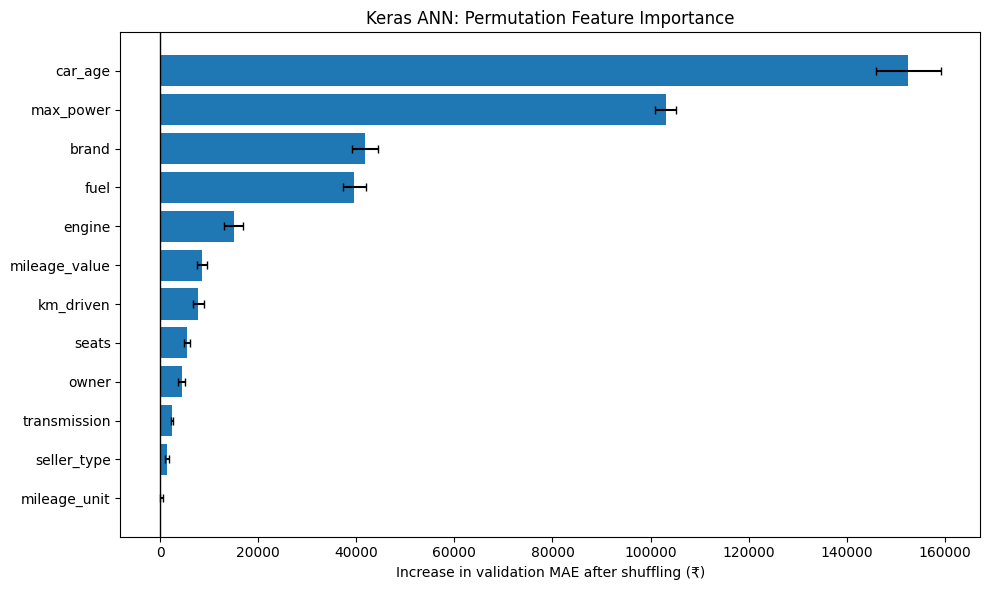

Permutation feature importance saved.


In [ ]:
importance_numeric_cols = list(numeric_scaler.feature_names_in_)
importance_cat_cols = list(ann_encoder.feature_names_in_)
importance_encoded_names = list(ann_encoder.get_feature_names_out())

importance_brand = np.asarray(
    X_val_brand, dtype="int32"
).reshape(-1, 1)

importance_other = np.asarray(
    X_val_other, dtype="float32"
)

importance_actual = np.asarray(
    y_val, dtype="float64"
).ravel()

numeric_check = numeric_scaler.transform(
    X_val[importance_numeric_cols]
)

encoded_check = ann_encoder.transform(
    X_val[importance_cat_cols]
)

if hasattr(encoded_check, "toarray"):
    encoded_check = encoded_check.toarray()

np.testing.assert_allclose(
    importance_other,
    np.hstack([numeric_check, encoded_check]),
    rtol=1e-5,
    atol=1e-6,
    err_msg="The feature order does not match X_val_other."
)

importance_groups = {"brand": None}

for position, feature in enumerate(importance_numeric_cols):
    importance_groups[feature] = [position]

numeric_count = len(importance_numeric_cols)

for feature in importance_cat_cols:
    positions = [
        numeric_count + position
        for position, name in enumerate(importance_encoded_names)
        if name.startswith(feature + "_")
    ]

    if not positions:
        raise ValueError(f"No encoded columns found for {feature}.")

    importance_groups[feature] = positions


def predict_for_importance(brand_values, other_values):
    scaled_predictions = selected_ann_model(
        {"brand": brand_values, "other": other_values},
        training=False
    ).numpy()

    target_predictions = selected_target_scaler.inverse_transform(
        scaled_predictions
    ).ravel().astype("float64")

    with np.errstate(over="raise", invalid="raise"):
        prices = (
            np.exp(target_predictions)
            if selected_uses_log
            else target_predictions
        )

    if not np.isfinite(prices).all():
        raise FloatingPointError("Predictions are not finite.")

    return prices


importance_reference_mae = mean_absolute_error(
    importance_actual,
    predict_for_importance(importance_brand, importance_other)
)

print(f"Original validation MAE: ₹{importance_reference_mae:,.2f}")

importance_rng = np.random.default_rng(SEED)
importance_permutations = [
    importance_rng.permutation(len(importance_actual))
    for _ in range(10)
]

importance_records = []

for feature, positions in importance_groups.items():

    for repeat, order in enumerate(importance_permutations, start=1):
        shuffled_brand = importance_brand.copy()
        shuffled_other = importance_other.copy()

        if feature == "brand":
            shuffled_brand = importance_brand[order].copy()
        else:
            shuffled_other[:, positions] = (
                importance_other[order][:, positions]
            )

        shuffled_prices = predict_for_importance(
            shuffled_brand,
            shuffled_other
        )

        shuffled_mae = mean_absolute_error(
            importance_actual,
            shuffled_prices
        )

        importance_records.append({
            "Feature": feature,
            "Repeat": repeat,
            "MAE increase (₹)": (
                shuffled_mae - importance_reference_mae
            )
        })

    print(f"Completed: {feature}")

permutation_importance_runs = pd.DataFrame(importance_records)

permutation_importance_results = (
    permutation_importance_runs
    .groupby("Feature")["MAE increase (₹)"]
    .agg(["mean", "std"])
    .rename(columns={
        "mean": "Mean MAE increase (₹)",
        "std": "SD across repeats (₹)"
    })
    .reset_index()
    .sort_values("Mean MAE increase (₹)", ascending=False)
    .reset_index(drop=True)
)

display(permutation_importance_results.round(2))

plot_data = permutation_importance_results.sort_values(
    "Mean MAE increase (₹)"
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["Feature"],
    plot_data["Mean MAE increase (₹)"],
    xerr=plot_data["SD across repeats (₹)"],
    capsize=3
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Increase in validation MAE after shuffling (₹)")
plt.title("Keras ANN: Permutation Feature Importance")
plt.tight_layout()

plt.savefig(
    backup_dir / "permutation_feature_importance.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

permutation_importance_results.to_csv(
    backup_dir / "permutation_feature_importance.csv",
    index=False
)

permutation_importance_runs.to_csv(
    backup_dir / "permutation_importance_runs.csv",
    index=False
)

print("Permutation feature importance saved.")

In [ ]:
import json
import joblib
import platform
import sklearn
import shutil

app_dir = backup_dir / "used_car_app"
artifacts_dir = app_dir / "artifacts"
artifacts_dir.mkdir(parents=True, exist_ok=True)

selected_ann_model.save(
    str(artifacts_dir / "car_price_model.keras")
)

app_preprocessing = {
    "numeric_scaler": numeric_scaler,
    "ann_encoder": ann_encoder,
    "target_scaler": selected_target_scaler,

    "numeric_columns": list(numeric_scaler.feature_names_in_),
    "categorical_columns": list(ann_encoder.feature_names_in_),

    "brand_to_id": dict(brand_to_id),
    "unknown_brand_id": 0,

    "uses_log_target": bool(selected_uses_log),
    "age_reference_year": int(REFERENCE_YEAR)
}

joblib.dump(
    app_preprocessing,
    artifacts_dir / "preprocessing.joblib"
)

app_metadata = {
    "selected_experiment": str(best_row["Experiment"]),
    "price_unit": "INR",
    "display_unit": "INR lakh",
    "requires_complete_inputs": True,

    "age_reference_year": int(REFERENCE_YEAR),
    "age_definition": "age_reference_year minus manufacturing_year",

    "brand_options": sorted(
        X_train["brand"].dropna().astype(str).unique().tolist()
    ),

    "categorical_options": {
        column: [str(value) for value in categories]
        for column, categories in zip(
            ann_encoder.feature_names_in_,
            ann_encoder.categories_
        )
    },

    "numeric_training_summary": {
        column: {
            "min": float(X_train[column].min()),
            "max": float(X_train[column].max()),
            "median": float(X_train[column].median())
        }
        for column in numeric_scaler.feature_names_in_
    },

    "uncertainty": {
        "method": "Monte Carlo dropout",
        "samples": 50,
        "lower_percentile": 5,
        "upper_percentile": 95,
        "calibrated": False,
        "validation_coverage_percent": float(mc_validation_coverage),
        "label": "Estimated model-uncertainty range"
    }
}

with open(
    artifacts_dir / "app_metadata.json", "w", encoding="utf-8"
) as file:
    json.dump(app_metadata, file, indent=2, ensure_ascii=False)

environment_versions = {
    "python": platform.python_version(),
    "tensorflow": tf.__version__,
    "scikit-learn": sklearn.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "joblib": joblib.__version__
}

with open(
    artifacts_dir / "training_environment.json", "w", encoding="utf-8"
) as file:
    json.dump(environment_versions, file, indent=2)

permutation_importance_results.to_csv(
    artifacts_dir / "feature_importance.csv",
    index=False
)

final_test_results.to_csv(
    artifacts_dir / "final_test_results.csv",
    index=False
)

loaded_app_model = tf.keras.models.load_model(
    str(artifacts_dir / "car_price_model.keras"),
    compile=False
)

loaded_preprocessing = joblib.load(
    artifacts_dir / "preprocessing.joblib"
)

check_cars = X_val.iloc[:5].copy()

check_brand = (
    check_cars["brand"]
    .map(loaded_preprocessing["brand_to_id"])
    .fillna(loaded_preprocessing["unknown_brand_id"])
    .to_numpy(dtype="int32")
    .reshape(-1, 1)
)

check_numeric = loaded_preprocessing["numeric_scaler"].transform(
    check_cars[loaded_preprocessing["numeric_columns"]]
)

check_categories = loaded_preprocessing["ann_encoder"].transform(
    check_cars[loaded_preprocessing["categorical_columns"]]
)

if hasattr(check_categories, "toarray"):
    check_categories = check_categories.toarray()

check_other = np.hstack(
    [check_numeric, check_categories]
).astype("float32")

np.testing.assert_array_equal(
    check_brand,
    np.asarray(X_val_brand[:5]).reshape(-1, 1)
)

np.testing.assert_allclose(
    check_other,
    np.asarray(X_val_other[:5]),
    rtol=1e-5,
    atol=1e-6
)

original_scaled = selected_ann_model(
    {
        "brand": np.asarray(X_val_brand[:5], dtype="int32").reshape(-1, 1),
        "other": np.asarray(X_val_other[:5], dtype="float32")
    },
    training=False
).numpy()

reloaded_scaled = loaded_app_model(
    {"brand": check_brand, "other": check_other},
    training=False
).numpy()

np.testing.assert_allclose(
    loaded_preprocessing["target_scaler"].inverse_transform(
        reloaded_scaled
    ),
    selected_target_scaler.inverse_transform(original_scaled),
    rtol=1e-5,
    atol=1e-6
)

print("Saved preprocessing matches the notebook inputs.")
print("Reloaded model predictions match the notebook predictions.")
print("Application artifacts are ready.")

print("\nSaved files:")
for saved_file in sorted(artifacts_dir.iterdir()):
    print("-", saved_file.name)

app_zip_path = shutil.make_archive(
    "/content/used_car_app_artifacts",
    "zip",
    root_dir=str(app_dir)
)

files.download(app_zip_path)

Saved preprocessing matches the notebook inputs.
Reloaded model predictions match the notebook predictions.
Application artifacts are ready.

Saved files:
- app_metadata.json
- car_price_model.keras
- feature_importance.csv
- final_test_results.csv
- preprocessing.joblib
- training_environment.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%pip install -q "fastapi>=0.115,<1" "pydantic>=2,<3" "uvicorn>=0.30,<1" "httpx>=0.27,<1"

api_code = r'''
from pathlib import Path
from datetime import datetime, timezone
from threading import Lock
import json

import joblib
import numpy as np
import pandas as pd
import tensorflow as tf

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, ConfigDict, Field

# Load files relative to this API file
BASE_DIR = Path(__file__).resolve().parent
ARTIFACTS = BASE_DIR / "artifacts"

MODEL = tf.keras.models.load_model(
    str(ARTIFACTS / "car_price_model.keras"),
    compile=False
)

PREP = joblib.load(ARTIFACTS / "preprocessing.joblib")

with open(ARTIFACTS / "app_metadata.json", encoding="utf-8") as file:
    META = json.load(file)

IMPORTANCE = pd.read_csv(ARTIFACTS / "feature_importance.csv")

LOG_DIR = BASE_DIR / "logs"
LOG_DIR.mkdir(exist_ok=True)

MODEL_LOCK = Lock()

app = FastAPI(title="Used-Car Price Estimator API", version="1.0")


# Required car details
class CarDetails(BaseModel):
    model_config = ConfigDict(
        extra="forbid",
        allow_inf_nan=False,
        str_strip_whitespace=True
    )

    brand: str = Field(min_length=1, max_length=80)

    car_age: float = Field(
        ge=0,
        description="Saved age_reference_year minus manufacturing year."
    )

    km_driven: float = Field(ge=0)
    mileage_value: float = Field(gt=0)
    engine: float = Field(gt=0)
    max_power: float = Field(gt=0)
    seats: int = Field(ge=1)

    fuel: str
    seller_type: str
    transmission: str
    owner: str
    mileage_unit: str


@app.get("/health")
def health():
    return {
        "status": "ready",
        "experiment": META["selected_experiment"]
    }


@app.get("/metadata")
def metadata():
    return META


@app.get("/feature-importance")
def feature_importance():
    return IMPORTANCE.to_dict(orient="records")


@app.post("/predict")
def predict(car: CarDetails):
    row = car.model_dump()
    notes = []

    # Match categorical values to the original training labels
    for column, options in META["categorical_options"].items():
        lookup = {value.casefold(): value for value in options}
        supplied = row[column].casefold()

        if supplied not in lookup:
            raise HTTPException(
                status_code=422,
                detail=f"Invalid {column}. Allowed values: {options}"
            )

        row[column] = lookup[supplied]

    # Preserve the original brand mapping
    brand_lookup = {
        value.casefold(): value
        for value in META["brand_options"]
    }

    row["brand"] = brand_lookup.get(
        row["brand"].casefold(),
        row["brand"]
    )

    brand_id = PREP["brand_to_id"].get(
        row["brand"],
        PREP["unknown_brand_id"]
    )

    if brand_id == PREP["unknown_brand_id"]:
        notes.append(
            "This brand uses the shared rare/unseen-brand representation."
        )

    # Identify inputs outside the numeric ranges seen during training
    for column, bounds in META["numeric_training_summary"].items():
        if not bounds["min"] <= row[column] <= bounds["max"]:
            notes.append(f"{column} is outside its observed training range.")

    frame = pd.DataFrame([row])

    # Apply the saved preprocessing without fitting anything
    try:
        with np.errstate(over="raise", invalid="raise"):
            numeric = PREP["numeric_scaler"].transform(
                frame[PREP["numeric_columns"]]
            )

            categories = PREP["ann_encoder"].transform(
                frame[PREP["categorical_columns"]]
            )

            if hasattr(categories, "toarray"):
                categories = categories.toarray()

            other = np.hstack(
                [numeric, categories]
            ).astype("float32")

    except (ValueError, FloatingPointError):
        raise HTTPException(
            status_code=422,
            detail="Numeric inputs could not be processed. Check their units and values."
        )

    if not np.isfinite(other).all():
        raise HTTPException(
            status_code=422,
            detail="Processed inputs contain non-finite values."
        )

    inputs = {
        "brand": np.array([[brand_id]], dtype="int32"),
        "other": other
    }

    def predict_price(dropout_on):
        scaled = MODEL(inputs, training=dropout_on).numpy()

        target = PREP["target_scaler"].inverse_transform(
            scaled
        ).astype("float64").ravel()[0]

        try:
            with np.errstate(over="raise", invalid="raise"):
                price = (
                    float(np.exp(target))
                    if PREP["uses_log_target"]
                    else float(target)
                )
        except FloatingPointError:
            raise HTTPException(
                status_code=422,
                detail="These inputs produced an invalid price estimate."
            )

        if not np.isfinite(price) or price <= 0:
            raise HTTPException(
                status_code=422,
                detail="These inputs produced an invalid price estimate."
            )

        return price

    # Serialize model calls and log writes within this process
    with MODEL_LOCK:
        # Normal prediction: dropout OFF
        point_price = predict_price(False)

        # Fifty stochastic predictions: dropout ON
        sample_count = int(META["uncertainty"]["samples"])

        samples = np.array([
            predict_price(True)
            for _ in range(sample_count)
        ])

        percentiles = [
            META["uncertainty"]["lower_percentile"],
            META["uncertainty"]["upper_percentile"]
        ]

        low, high = np.percentile(samples, percentiles)

        result = {
            "prediction_inr": point_price,
            "prediction_lakh": point_price / 100000,
            "low_inr": float(low),
            "high_inr": float(high),
            "low_lakh": float(low / 100000),
            "high_lakh": float(high / 100000),
            "mc_samples": sample_count,
            "range_label": META["uncertainty"]["label"],
            "range_calibrated": False,
            "validation_coverage_percent":
                META["uncertainty"]["validation_coverage_percent"],
            "age_reference_year": META["age_reference_year"],
            "notes": notes
        }

        # Record each successful prediction
        log_entry = {
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
            "experiment": META["selected_experiment"],
            "inputs": row,
            "result": result
        }

        with open(
            LOG_DIR / "predictions.jsonl",
            "a",
            encoding="utf-8"
        ) as file:
            file.write(
                json.dumps(log_entry, ensure_ascii=False, allow_nan=False)
                + "\n"
            )

    return result
'''

api_path = app_dir / "api.py"
api_path.write_text(api_code, encoding="utf-8")

import importlib.util
import sys
from fastapi.testclient import TestClient

api_spec = importlib.util.spec_from_file_location(
    "used_car_api", api_path
)
api_module = importlib.util.module_from_spec(api_spec)
sys.modules["used_car_api"] = api_module
api_spec.loader.exec_module(api_module)

example_request = json.loads(X_val.iloc[0].to_json())

with TestClient(api_module.app) as client:
    response = client.post("/predict", json=example_request)

    print("Prediction HTTP status:", response.status_code)
    assert response.status_code == 200, response.text

    api_result = response.json()

    expected_scaled = selected_ann_model(
        {
            "brand": np.asarray(
                X_val_brand[:1], dtype="int32"
            ).reshape(-1, 1),
            "other": np.asarray(X_val_other[:1], dtype="float32")
        },
        training=False
    ).numpy()

    expected_target = selected_target_scaler.inverse_transform(
        expected_scaled
    ).ravel().astype("float64")[0]

    expected_price = (
        float(np.exp(expected_target))
        if selected_uses_log
        else float(expected_target)
    )

    np.testing.assert_allclose(
        api_result["prediction_inr"],
        expected_price,
        rtol=1e-5,
        atol=0.10
    )

    invalid_request = {**example_request, "km_driven": -1}
    invalid_response = client.post("/predict", json=invalid_request)

    assert invalid_response.status_code == 422

display(pd.DataFrame([{
    "Prediction (₹ lakh)": api_result["prediction_lakh"],
    "Low (₹ lakh)": api_result["low_lakh"],
    "High (₹ lakh)": api_result["high_lakh"],
    "MC samples": api_result["mc_samples"]
}]).round(3))

print("API point prediction matches the notebook.")
print("Negative kilometres correctly rejected.")
print("Prediction log saved.")
print("API file created:", api_path)

api_zip_path = shutil.make_archive(
    "/content/used_car_app_with_api",
    "zip",
    root_dir=str(app_dir)
)
files.download(api_zip_path)

Prediction HTTP status: 200


,Prediction (₹ lakh),Low (₹ lakh),High (₹ lakh),MC samples
0,1.821,1.459,2.065,50


API point prediction matches the notebook.
Negative kilometres correctly rejected.
Prediction log saved.
API file created: /content/used_car_ann001_backup/used_car_app/api.py


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%pip install -q "streamlit==1.64.0" "requests>=2.31,<3"

import ast
import io
import shutil
import zipfile
from pathlib import Path
from datetime import datetime
from google.colab import files

app_dir = Path(app_dir).resolve()

if not (app_dir / "api.py").exists():
    raise FileNotFoundError(
        "Your API file is missing. Complete Cell 58 first."
    )

print("Upload AutoValue_Design_Update.zip")
uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Please upload only the design-update ZIP.")

zip_bytes = next(iter(uploaded.values()))

with zipfile.ZipFile(io.BytesIO(zip_bytes)) as archive:
    new_ui = archive.read("streamlit_app.py")
    new_theme = archive.read(".streamlit/config.toml")

ast.parse(new_ui.decode("utf-8"))

backup_folder = (
    app_dir
    / "ui_backups"
    / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)

updates = {
    "streamlit_app.py": new_ui,
    ".streamlit/config.toml": new_theme,
}

for relative_path, content in updates.items():
    destination = app_dir / relative_path

    if destination.exists():
        backup_path = backup_folder / relative_path
        backup_path.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(destination, backup_path)

    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_bytes(content)

print("Advanced design installed successfully.")
print("Previous interface backed up at:", backup_folder)
print("Now rerun Cell 60 and open its Streamlit link.")

Upload AutoValue_Design_Update.zip


Saving AutoValue_Design_Update.zip to AutoValue_Design_Update (1).zip
Advanced design installed successfully.
Previous interface backed up at: /content/used_car_ann001_backup/used_car_app/ui_backups/20260930_172554_775936
Now rerun Cell 60 and open its Streamlit link.


In [ ]:
import os
import sys
import time
import socket
import subprocess
from pathlib import Path
from urllib.parse import urlparse
from html import escape

import requests
from google.colab import output
from IPython.display import HTML, display

app_dir = Path(app_dir).resolve()

for filename in ("api.py", "streamlit_app.py"):
    if not (app_dir / filename).exists():
        raise FileNotFoundError(
            f"{filename} is missing. Check Cells 58 and 59."
        )

server_logs = app_dir / "logs"
server_logs.mkdir(exist_ok=True)

api_log_path = server_logs / "api_server.log"
ui_log_path = server_logs / "streamlit_server.log"


def stop_previous_process(variable_name):
    """Stop only a server previously started by this cell."""
    process = globals().get(variable_name)

    if isinstance(process, subprocess.Popen):
        if process.poll() is None:
            process.terminate()
            try:
                process.wait(timeout=10)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait(timeout=5)


stop_previous_process("car_ui_process")
stop_previous_process("car_api_process")


def check_port_available(port):
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as connection:
        try:
            connection.bind(("127.0.0.1", port))
        except OSError as exc:
            raise RuntimeError(
                f"Port {port} is already used by another process."
            ) from exc


check_port_available(8000)
check_port_available(8501)


def wait_for_service(url, process, log_path, timeout=120):
    """Wait for a server to start and print logs if it fails."""
    deadline = time.monotonic() + timeout

    while time.monotonic() < deadline:
        if process.poll() is not None:
            break

        try:
            response = requests.get(url, timeout=3)
            if response.status_code == 200:
                return response
        except requests.RequestException:
            pass

        time.sleep(1)

    print(
        log_path.read_text(
            encoding="utf-8", errors="replace"
        )[-6000:]
    )
    raise RuntimeError(
        f"Server startup failed. Check the log above: {log_path}"
    )

api_environment = os.environ.copy()
api_environment["CUDA_VISIBLE_DEVICES"] = "-1"
api_environment["PYTHONUNBUFFERED"] = "1"

with api_log_path.open("w", encoding="utf-8") as log_file:
    car_api_process = subprocess.Popen(
        [
            sys.executable, "-m", "uvicorn",
            "api:app",
            "--host", "127.0.0.1",
            "--port", "8000",
            "--workers", "1",
        ],
        cwd=str(app_dir),
        env=api_environment,
        stdout=log_file,
        stderr=subprocess.STDOUT,
    )

print("Starting prediction API...")

health_response = wait_for_service(
    "http://127.0.0.1:8000/health",
    car_api_process,
    api_log_path,
)

print("API ready:", health_response.json())


app_url = output.eval_js(
    "google.colab.kernel.proxyPort(8501)"
)
proxy_hostname = urlparse(app_url).hostname

if not proxy_hostname:
    raise RuntimeError(
        "Colab did not return a valid application address."
    )


ui_environment = os.environ.copy()
ui_environment["CAR_API_URL"] = "http://127.0.0.1:8000"
ui_environment["PYTHONUNBUFFERED"] = "1"

with ui_log_path.open("w", encoding="utf-8") as log_file:
    car_ui_process = subprocess.Popen(
        [
            sys.executable, "-m", "streamlit",
            "run", "streamlit_app.py",
            "--server.address", "127.0.0.1",
            "--server.port", "8501",
            "--server.headless", "true",
            "--browser.serverAddress", proxy_hostname,
            "--browser.gatherUsageStats", "false",
        ],
        cwd=str(app_dir),
        env=ui_environment,
        stdout=log_file,
        stderr=subprocess.STDOUT,
    )

print("Starting Streamlit...")

wait_for_service(
    "http://127.0.0.1:8501/_stcore/health",
    car_ui_process,
    ui_log_path,
)

print("Both servers are ready.")
print("Click the link below to open your app in a separate tab.")
print("Keep the Colab runtime connected while using the app.")

display(HTML(
    f'<a href="{escape(app_url, quote=True)}" '
    'target="_blank" rel="noopener noreferrer" '
    'style="display:inline-block; padding:14px 22px; '
    'background:#2878B5; color:white; border-radius:8px; '
    'text-decoration:none; font-size:18px; font-weight:bold;">'
    '🚗 Open Streamlit app in a new tab'
    '</a>'
))

Starting prediction API...
API ready: {'status': 'ready', 'experiment': 'ANN_013'}
Starting Streamlit...
Both servers are ready.
Click the link below to open your app in a separate tab.
Keep the Colab runtime connected while using the app.


In [ ]:
# Cell 61: Package the project — corrected version

from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
import json
import platform
import shutil
import zipfile
import pandas as pd
from google.colab import files

app_dir = Path(app_dir).resolve()
backup_dir = Path(backup_dir).resolve()
artifacts_dir = app_dir / "artifacts"
results_dir = app_dir / "results"

results_dir.mkdir(exist_ok=True)

# 1. Check essential files.
required_files = [
    "api.py",
    "streamlit_app.py",
    "artifacts/car_price_model.keras",
    "artifacts/preprocessing.joblib",
    "artifacts/app_metadata.json",
    "artifacts/feature_importance.csv",
    "artifacts/final_test_results.csv",
]

missing = [
    name for name in required_files
    if not (app_dir / name).is_file()
]

if missing:
    raise FileNotFoundError(
        "Required files are missing:\n" + "\n".join(missing)
    )

# 2. Record package versions.
packages = [
    "tensorflow",
    "scikit-learn",
    "numpy",
    "pandas",
    "joblib",
    "fastapi",
    "pydantic",
    "uvicorn",
    "streamlit",
    "requests",
    "altair",
    "matplotlib",
    "httpx",
]

requirements = []

for package in packages:
    try:
        requirements.append(f"{package}=={version(package)}")
    except PackageNotFoundError:
        if package == "tensorflow":
            requirements.append(
                f"tensorflow-cpu=={version('tensorflow-cpu')}"
            )
        else:
            raise RuntimeError(
                f"Cannot find the installed version of {package}."
            )

(app_dir / "requirements.txt").write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8",
)

# 3. Collect available analysis files.
keywords = (
    "experiment",
    "comparison",
    "results",
    "history",
    "residual",
    "importance",
    "dropout",
    "learning_curve",
    "validation",
    "final_test",
)

for source in sorted(backup_dir.iterdir()):
    if not source.is_file():
        continue

    is_analysis_file = (
        source.suffix.lower() in {".csv", ".png", ".npy"}
        and any(word in source.name.lower() for word in keywords)
    )

    is_numpy_weights = (
        source.name == "scratch_ann_best_weights.npz"
    )

    if is_analysis_file or is_numpy_weights:
        shutil.copy2(source, results_dir / source.name)

shutil.copy2(
    artifacts_dir / "final_test_results.csv",
    results_dir / "final_test_results.csv",
)

# 4. Read metadata and actual saved results.
metadata = json.loads(
    (artifacts_dir / "app_metadata.json").read_text(
        encoding="utf-8"
    )
)

test_results = pd.read_csv(
    artifacts_dir / "final_test_results.csv"
)

reference_year = metadata["age_reference_year"]
coverage = float(
    metadata["uncertainty"]["validation_coverage_percent"]
)
python_version = platform.python_version()

# 5. Build README using separate strings.
# This avoids the unfinished triple-quoted-string error.
readme_lines = [
    "# AutoValue: Used-Car Price Estimator",
    "",
    "MSc neural-network project using the Indian CarDekho dataset.",
    "",
    "## Project components",
    "",
    "- Linear regression baseline.",
    "- Keras ANN with learned brand embedding.",
    "- NumPy ANN implemented from scratch.",
    "- Optimizer, learning-rate, loss and target-transform experiments.",
    "- Residual analysis by fuel and actual-price band.",
    "- Monte Carlo dropout using 50 draws.",
    "- Validation-set permutation feature importance.",
    "- FastAPI prediction service and prediction logging.",
    "- Streamlit interface with age/kilometre what-if controls.",
    "",
    "## Environment",
    "",
    f"Packaged from Python {python_version}.",
    "Installed dependency versions are in requirements.txt.",
    "A clean-environment installation check is still required.",
    "",
    "## Installation",
    "",
    "Extract the ZIP and open a terminal in its folder.",
    "",
    "Create a virtual environment:",
    "",
    "    python -m venv .venv",
    "",
    "Activate on Windows PowerShell:",
    "",
    r"    .venv\Scripts\Activate.ps1",
    "",
    "Activate on macOS/Linux:",
    "",
    "    source .venv/bin/activate",
    "",
    "Install dependencies:",
    "",
    "    python -m pip install -r requirements.txt",
    "",
    "## Run the application",
    "",
    "In the first terminal, start the API:",
    "",
    "    python -m uvicorn api:app --host 127.0.0.1 --port 8000 --workers 1",
    "",
    "In a second terminal, activate the same environment and run:",
    "",
    "    python -m streamlit run streamlit_app.py",
    "",
    "Open the Streamlit address printed in the terminal.",
    "API documentation: http://127.0.0.1:8000/docs",
    "For the Colab demonstration, run notebook Cell 60 instead.",
    "",
    "## API endpoints",
    "",
    "- GET /health",
    "- GET /metadata",
    "- GET /feature-importance",
    "- POST /predict",
    "",
    "Successful predictions are logged in logs/predictions.jsonl.",
    "Runtime logs are excluded from this distribution ZIP.",
    "",
    "## Input interpretation",
    "",
    f"Vehicle age = {reference_year} - manufacturing_year.",
    "Keep this reference year fixed to match training.",
    "Estimates reflect the training dataset, not live market quotations.",
    "Enter actual vehicle specifications and the correct mileage unit.",
    "Individual values and categories are validated, but the application",
    "does not fully verify that a combination describes a real vehicle.",
    "",
    "## Prediction and uncertainty",
    "",
    "The main price is predicted with dropout switched off.",
    "The range uses the 5th and 95th percentiles of 50 MC-dropout draws.",
    "This is an uncalibrated model-uncertainty range.",
    "It is not a guaranteed 90% interval for actual selling prices.",
    f"Observed validation coverage: {coverage:.2f}%.",
    "",
    "## Evaluation",
    "",
    "Final test metrics: results/final_test_results.csv",
    "Test data was reserved for final evaluation.",
    "Do not use test results for further model selection or tuning.",
    "The linear baseline had non-positive predictions, so its log-price",
    "R² is undefined. Those predictions remain in the raw-price metrics.",
    "",
    "## Feature importance",
    "",
    "Permutation importance was calculated on validation data.",
    "It shows global model reliance, not causation or an explanation",
    "of an individual prediction. Correlated features can share importance.",
    "",
    "## Remaining submission items",
    "",
    "- Include the final training notebook separately.",
    "- Include the final report and experiment tables.",
    "- Verify installation in a clean environment.",
    "- Record the application demonstration.",
    "- Include a Git repository with contributions from both members.",
    "",
    "The training notebook contains preprocessing, split construction,",
    "seeds, experiments, and the from-scratch NumPy implementation.",
]

(app_dir / "README.md").write_text(
    "\n".join(readme_lines) + "\n",
    encoding="utf-8",
)

# 6. Create the distribution ZIP.
zip_path = Path("/content/AutoValue_Project_Package.zip")

excluded_folders = {
    "__pycache__",
    ".venv",
    ".git",
    "ui_backups",
    "logs",
}

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:

    for source in sorted(app_dir.rglob("*")):
        if not source.is_file():
            continue

        relative_path = source.relative_to(app_dir)

        if any(
            part in excluded_folders
            for part in relative_path.parts
        ):
            continue

        if source.suffix == ".pyc":
            continue

        archive.write(
            source,
            arcname=relative_path.as_posix(),
        )

# 7. Show results and download.
print("Project package created successfully.")
print("README.md created.")
print("requirements.txt created.")
print("Python version:", python_version)
print(
    "ZIP size:",
    round(zip_path.stat().st_size / 1_000_000, 2),
    "MB",
)

print("\nSaved final test results:")
display(test_results)

print("\nAnalysis files included:")
for source in sorted(results_dir.iterdir()):
    if source.is_file():
        print("-", source.name)

files.download(str(zip_path))

Project package created successfully.
README.md created.
requirements.txt created.
Python version: 3.13.15
ZIP size: 0.76 MB

Saved final test results:


,Model,MAE (₹),RMSE (₹),R2 (raw price),MAPE (%),R2 (log price),Non-positive predictions
0,Linear regression,139438.175622,269481.736482,0.725626,46.338992,NaN,63
1,Keras ANN,77564.603090,150234.364412,0.914725,16.926017,0.908459,0
2,NumPy ANN,78488.848264,160592.075289,0.902561,17.256326,0.907408,0



Analysis files included:
- ann_001_history.csv
- baseline_validation.csv
- experiment_plan.csv
- experiment_results.csv
- final_test_predictions.csv
- final_test_results.csv
- keras_test_residuals.csv
- keras_vs_numpy_validation.csv
- learning_rate_comparison.csv
- loss_comparison.csv
- mc_dropout_validation.csv
- mc_dropout_validation_samples.npy
- optimizer_comparison.csv
- permutation_feature_importance.csv
- permutation_feature_importance.png
- permutation_importance_runs.csv
- residual_boxplots.png
- residuals_by_fuel.csv
- residuals_by_price_band.csv
- scratch_ann_best_weights.npz
- scratch_learning_curves.png
- scratch_training_history.csv
- scratch_validation_results.csv
- target_comparison.csv
- validation_experiment_summary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>